In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
print(os.listdir('/content/drive/MyDrive/'))

['Colab Notebooks', '8.png', '2.png', '19.png', '18.png', '13.png', '20.png', '11.png', '3.png', '14.png', '9.png', '1.png', '17.png', '6.png', '16.png', '4.png', '15.png', '12.png', '10.png', '7.png', '5.png', 'jeux', 'JEUX', 'Byzantine_monograms', 'compare_models_whisper.py', 'Séance 7', 'exemples', 'JURAFSKY', 'ADMINISTRATIF', 'LIVRES', 'anglais', 'Blogs Mots&Pouvoir', 'sranga', 'CV', 'Memoire M1', 'Byzantine_monograms (1).tar', 'Byzantine_monograms.tar', 'bhai_classification', 'bhai_classification.zip', 'Rapport_OCR_Sawadogo_Diouhe_v2 (2).gdoc', 'Rapport_OCR_Sawadogo_Diouhe_v2 (1).gdoc', 'Rapport_OCR_Sawadogo_Diouhe_v2.gdoc']


In [4]:
print(os.listdir('/content/drive/MyDrive/bhai_classification/'))

['requirements.txt', 'README.md', '.venv', 'data', 'splits', 'results_v1', 'results']


In [5]:
print(os.listdir('/content/drive/MyDrive/bhai_classification/data/'))

['zacos.csv', 'adolfo.csv', 'Adolfo', 'Zacos']


In [6]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset, WeightedRandomSampler
from torchvision import transforms, models
from PIL import Image
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# ─── CHEMINS À AJUSTER ───────────────────────────────────────────────────────
ADOLFO_CSV    = '/content/drive/MyDrive/bhai_classification/data/adolfo.csv'
ZACOS_CSV     = '/content/drive/MyDrive/bhai_classification/data/zacos.csv'
ADOLFO_IMGDIR = '/content/drive/MyDrive/bhai_classification/data/Adolfo/'
ZACOS_IMGDIR  = '/content/drive/MyDrive/bhai_classification/data/Zacos/'
SPLITS_DIR    = '/content/drive/MyDrive/bhai_classification/splits'
RESULTS_DIR   = '/content/drive/MyDrive/bhai_classification/results'
# ─────────────────────────────────────────────────────────────────────────────

N_SPLITS      = 5
VAL_SIZE      = 0.15
RANDOM_STATE  = 7
BATCH_SIZE    = 16
NUM_EPOCHS    = 25
LEARNING_RATE = 1e-4
IMG_SIZE      = 224
NUM_WORKERS   = 2
NUM_CLASSES   = 4
LABEL_NAMES   = ['M0', 'M1', 'M2', 'M3']

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(SPLITS_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')
print('✓ Configuration chargée')

Device : cuda
✓ Configuration chargée


In [7]:
def load_and_merge():
    adolfo = pd.read_csv(ADOLFO_CSV)
    zacos  = pd.read_csv(ZACOS_CSV)
    adolfo['image_path'] = adolfo['monogram_id'].astype(str) + '.jpg'
    adolfo['collection'] = 'adolfo'
    adolfo = adolfo[['image_path', 'quality_label', 'collection']]
    zacos['image_path'] = zacos['filename'].astype(str)
    zacos['collection'] = 'zacos'
    zacos = zacos[['image_path', 'quality_label', 'collection']]
    df = pd.concat([adolfo, zacos], ignore_index=True)
    df = df.rename(columns={'quality_label': 'label'})
    print(f'Dataset combiné : {len(df)} images')
    print(f'Distribution :')
    print(df['label'].value_counts().sort_index().rename({0:'M0',1:'M1',2:'M2',3:'M3'}))
    return df

df_global = load_and_merge()
print('\n✓ CSV chargés et fusionnés')

Dataset combiné : 625 images
Distribution :
label
M0     80
M1    272
M2    244
M3     29
Name: count, dtype: int64

✓ CSV chargés et fusionnés


In [8]:
def create_splits(df):
    X = df['image_path'].values
    y = df['label'].values
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    for fold, (trainval_idx, test_idx) in enumerate(skf.split(X, y)):
        fold_dir = os.path.join(SPLITS_DIR, f'fold_{fold}')
        os.makedirs(fold_dir, exist_ok=True)
        df_trainval = df.iloc[trainval_idx]
        df_test     = df.iloc[test_idx]
        df_train, df_val = train_test_split(
            df_trainval, test_size=VAL_SIZE,
            stratify=df_trainval['label'], random_state=RANDOM_STATE
        )
        df_train.to_csv(os.path.join(fold_dir, 'train.csv'), index=False)
        df_val.to_csv(  os.path.join(fold_dir, 'val.csv'),   index=False)
        df_test.to_csv( os.path.join(fold_dir, 'test.csv'),  index=False)
        print(f'Fold {fold} | train={len(df_train)} | val={len(df_val)} | test={len(df_test)}')
    all_test = []
    for fold in range(N_SPLITS):
        df_t = pd.read_csv(os.path.join(SPLITS_DIR, f'fold_{fold}', 'test.csv'))
        all_test.extend(df_t['image_path'].tolist())
    assert len(all_test) == len(set(all_test)), 'ERREUR : splits non exclusifs !'
    print('\n✓ Splits créés — sets de test mutuellement exclusifs.')

if not os.path.exists(os.path.join(SPLITS_DIR, 'fold_0')):
    create_splits(df_global)
else:
    print('✓ Splits déjà existants — on passe.')

✓ Splits déjà existants — on passe.


In [9]:
import tempfile

def get_transforms(split='train'):
    normalize = transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
    if split == 'train':
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomVerticalFlip(),           # nouveau
            transforms.RandomRotation(30),             # augmenté de 15 à 30
            transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),  # renforcé
            transforms.RandomGrayscale(p=0.1),         # nouveau
            transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),  # nouveau
            transforms.ToTensor(),
            normalize,
        ])
    else:
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            normalize,
        ])

class AdolfoDataset(Dataset):
    def __init__(self, csv_path, split='train'):
        self.df = pd.read_csv(csv_path)
        self.transform = get_transforms(split)
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(ADOLFO_IMGDIR, str(row['monogram_id']) + '.jpg')
        image = Image.open(img_path).convert('RGB')
        return self.transform(image), int(row['quality_label'])

class ZacosDataset(Dataset):
    def __init__(self, csv_path, split='train'):
        self.df = pd.read_csv(csv_path)
        self.transform = get_transforms(split)
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(ZACOS_IMGDIR, str(row['filename']))
        image = Image.open(img_path).convert('RGB')
        return self.transform(image), int(row['quality_label'])

def load_fold_dataset(fold, split):
    df = pd.read_csv(os.path.join(SPLITS_DIR, f'fold_{fold}', f'{split}.csv'))
    df_a = df[df['collection']=='adolfo'].reset_index(drop=True)
    df_z = df[df['collection']=='zacos'].reset_index(drop=True)
    tmp_a = os.path.join(tempfile.gettempdir(), f'adolfo_{split}_{fold}.csv')
    tmp_z = os.path.join(tempfile.gettempdir(), f'zacos_{split}_{fold}.csv')
    df_a[['image_path','label']].rename(
        columns={'image_path':'monogram_id','label':'quality_label'}
    ).assign(monogram_id=lambda x: x['monogram_id'].str.replace('.jpg','',regex=False)
    ).to_csv(tmp_a, index=False)
    df_z[['image_path','label']].rename(
        columns={'image_path':'filename','label':'quality_label'}
    ).to_csv(tmp_z, index=False)
    return ConcatDataset([AdolfoDataset(tmp_a, split), ZacosDataset(tmp_z, split)])

print('✓ Datasets prêts — augmentation renforcée')

✓ Datasets prêts — augmentation renforcée


In [10]:
def get_model(model_name):
    if model_name == 'resnet18':
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        for name, param in model.named_parameters():
            if 'layer4' not in name and 'fc' not in name:
                param.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    elif model_name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        for name, param in model.named_parameters():
            if 'layer4' not in name and 'fc' not in name:
                param.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    elif model_name == 'efficientnet':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        # Dégeler les 4 derniers blocs au lieu de 2
        for name, param in model.named_parameters():
            if 'features.5' not in name and 'features.6' not in name and \
               'features.7' not in name and 'features.8' not in name and \
               'classifier' not in name:
                param.requires_grad = False
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)

    elif model_name == 'vit_tiny':
        import timm
        model = timm.create_model('vit_tiny_patch16_224', pretrained=True, num_classes=NUM_CLASSES)
        for name, param in model.named_parameters():
            if 'blocks.9' not in name and 'blocks.10' not in name and \
               'blocks.11' not in name and 'head' not in name and 'norm' not in name:
                param.requires_grad = False

    elif model_name == 'dinov2':
        from transformers import AutoModel

        backbone = AutoModel.from_pretrained('facebook/dinov2-small')

        # Dégeler les 2 derniers blocs (10 et 11) au lieu d'un seul
        for name, param in backbone.named_parameters():
            if 'encoder.layer.10' not in name and 'encoder.layer.11' not in name:
                param.requires_grad = False

        class DINOv2Classifier(nn.Module):
            def __init__(self, backbone, num_classes):
                super().__init__()
                self.backbone   = backbone
                self.classifier = nn.Linear(384, num_classes)

            def forward(self, x):
                outputs   = self.backbone(x)
                cls_token = outputs.last_hidden_state[:, 0]
                return self.classifier(cls_token)

        model = DINOv2Classifier(backbone, NUM_CLASSES)

    else:
        raise ValueError(f'Modèle inconnu : {model_name}')

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    print(f'  {model_name} — paramètres entraînables : {trainable:,} / {total:,} ({100*trainable//total}%)')

    return model

print('✓ Modèles définis')

✓ Modèles définis


In [11]:
def get_class_weights(dataset):
    labels = []
    for ds in dataset.datasets:
        labels.extend(ds.df['quality_label'].tolist())
    labels  = np.array(labels)
    weights = compute_class_weight('balanced', classes=np.unique(labels), y=labels)
    print(f'  Class weights : M0={weights[0]:.3f} | M1={weights[1]:.3f} | M2={weights[2]:.3f} | M3={weights[3]:.3f}')
    return torch.FloatTensor(weights).to(device)

def get_sampler(dataset):
    labels = []
    for ds in dataset.datasets:
        labels.extend(ds.df['quality_label'].tolist())
    labels = np.array(labels)
    _, counts = np.unique(labels, return_counts=True)
    sample_weights = np.array([1.0/counts[l] for l in labels])
    return WeightedRandomSampler(torch.FloatTensor(sample_weights), len(sample_weights), replacement=True)

def run_epoch(model, loader, optimizer, criterion, training=True):
    model.train() if training else model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training: optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    cm  = confusion_matrix(all_labels, all_preds, labels=[0,1,2,3])
    return avg_loss, acc, f1, cm

def plot_curves(history, model_name, fold):
    """Trace les courbes train/val loss et accuracy pour détecter l'overfitting."""
    epochs = range(1, len(history['train_loss'])+1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    axes[0].plot(epochs, history['train_loss'], 'b-', label='Train Loss')
    axes[0].plot(epochs, history['val_loss'],   'r-', label='Val Loss')
    axes[0].set_title(f'{model_name} — Fold {fold} — Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Accuracy
    axes[1].plot(epochs, history['train_acc'], 'b-', label='Train Accuracy')
    axes[1].plot(epochs, history['val_acc'],   'r-', label='Val Accuracy')
    axes[1].set_title(f'{model_name} — Fold {fold} — Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    fig_path = os.path.join(RESULTS_DIR, f'curves_{model_name}_fold{fold}.png')
    plt.savefig(fig_path, dpi=150)
    plt.show()
    plt.close()

def train_model(model_name):
    print(f"\n{'='*60}")
    print(f'  Modèle : {model_name} | {NUM_EPOCHS} epochs | {N_SPLITS} folds')
    print(f"{'='*60}")

    fold_results = []
    summed_cm    = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)

    for fold in range(N_SPLITS):
        print(f'\n--- Fold {fold} ---')
        checkpoint = os.path.join(RESULTS_DIR, f'{model_name}_fold{fold}.pth')

        train_ds = load_fold_dataset(fold, 'train')
        val_ds   = load_fold_dataset(fold, 'val')
        test_ds  = load_fold_dataset(fold, 'test')

        class_weights = get_class_weights(train_ds)
        criterion     = nn.CrossEntropyLoss(weight=class_weights)
        sampler       = get_sampler(train_ds)

        train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,   num_workers=NUM_WORKERS)
        val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,     num_workers=NUM_WORKERS)
        test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,     num_workers=NUM_WORKERS)

        model     = get_model(model_name).to(device)
        optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.1)

        history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
        best_val_acc = 0.0
        best_val_f1  = 0.0

        for epoch in range(NUM_EPOCHS):
            train_loss, train_acc, _, _    = run_epoch(model, train_loader, optimizer, criterion, training=True)
            val_loss,   val_acc,   val_f1, _ = run_epoch(model, val_loader, optimizer, criterion, training=False)
            scheduler.step()

            history['train_loss'].append(train_loss)
            history['val_loss'].append(val_loss)
            history['train_acc'].append(train_acc)
            history['val_acc'].append(val_acc)

            print(f'  Epoch {epoch+1:02d}/{NUM_EPOCHS} | '
                  f'train_loss={train_loss:.4f} train_acc={train_acc:.4f} | '
                  f'val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_f1={val_f1:.4f}')

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_val_f1  = val_f1
                torch.save(model.state_dict(), checkpoint)

        # Courbes train/val
        plot_curves(history, model_name, fold)

        # Évaluation finale sur test
        model.load_state_dict(torch.load(checkpoint))
        _, test_acc, test_f1, test_cm = run_epoch(model, test_loader, optimizer, criterion, training=False)
        summed_cm += test_cm

        print(f'\n  ✓ Fold {fold} — test_acc={test_acc:.4f} | test_f1={test_f1:.4f}')

        fold_results.append({
            'fold':     fold,
            'val_acc':  best_val_acc,
            'val_f1':   best_val_f1,
            'test_acc': test_acc,
            'test_f1':  test_f1,
            'confusion_matrix': test_cm.tolist(),
            'history':  history
        })

    # Agrégation
    test_accs = [r['test_acc'] for r in fold_results]
    test_f1s  = [r['test_f1']  for r in fold_results]
    best_fold = int(np.argmax(test_accs))

    summary = {
        'model':         model_name,
        'mean_test_acc': float(np.mean(test_accs)),
        'std_test_acc':  float(np.std(test_accs)),
        'mean_test_f1':  float(np.mean(test_f1s)),
        'std_test_f1':   float(np.std(test_f1s)),
        'best_fold':     best_fold,
        'best_test_acc': float(test_accs[best_fold]),
        'summed_cm':     summed_cm.tolist(),
        'fold_details':  fold_results
    }

    out = os.path.join(RESULTS_DIR, f'results_{model_name}.json')
    with open(out, 'w') as f:
        json.dump(summary, f, indent=2)

    # Matrice de confusion sommée
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(summed_cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=ax)
    ax.set_xlabel('Prédit')
    ax.set_ylabel('Réel')
    ax.set_title(f'Matrice de confusion sommée — {model_name} (5 folds)')
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, f'cm_sommee_{model_name}.png'), dpi=150)
    plt.show()
    plt.close()

    print(f"\n{'='*60}")
    print(f'  RÉSUMÉ {model_name}')
    print(f'  test_acc : {summary["mean_test_acc"]:.4f} ± {summary["std_test_acc"]:.4f}')
    print(f'  test_f1  : {summary["mean_test_f1"]:.4f} ± {summary["std_test_f1"]:.4f}')
    print(f'  meilleur fold : {best_fold} (acc={summary["best_test_acc"]:.4f})')
    print(f'  Résultats sauvegardés dans : {out}')
    print(f"{'='*60}")

    return summary

print('✓ Fonctions d\'entraînement prêtes')

✓ Fonctions d'entraînement prêtes



  Modèle : resnet18 | 25 epochs | 5 folds

--- Fold 0 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 158MB/s]


  resnet18 — paramètres entraînables : 8,395,780 / 11,178,564 (75%)
  Epoch 01/25 | train_loss=1.0258 train_acc=0.4306 | val_loss=1.8888 val_acc=0.2133 val_f1=0.1456
  Epoch 02/25 | train_loss=0.5857 train_acc=0.4941 | val_loss=1.1275 val_acc=0.3333 val_f1=0.3212
  Epoch 03/25 | train_loss=0.4153 train_acc=0.5576 | val_loss=1.1882 val_acc=0.2800 val_f1=0.2586
  Epoch 04/25 | train_loss=0.4708 train_acc=0.5224 | val_loss=1.1236 val_acc=0.2933 val_f1=0.2774
  Epoch 05/25 | train_loss=0.4863 train_acc=0.5694 | val_loss=1.1084 val_acc=0.2933 val_f1=0.2422
  Epoch 06/25 | train_loss=0.4059 train_acc=0.5859 | val_loss=1.2226 val_acc=0.3067 val_f1=0.2427
  Epoch 07/25 | train_loss=0.3905 train_acc=0.6494 | val_loss=1.2384 val_acc=0.2933 val_f1=0.2683
  Epoch 08/25 | train_loss=0.3255 train_acc=0.6612 | val_loss=1.2179 val_acc=0.3733 val_f1=0.3167
  Epoch 09/25 | train_loss=0.2936 train_acc=0.6753 | val_loss=1.6434 val_acc=0.4533 val_f1=0.3258
  Epoch 10/25 | train_loss=0.2482 train_acc=0.6941

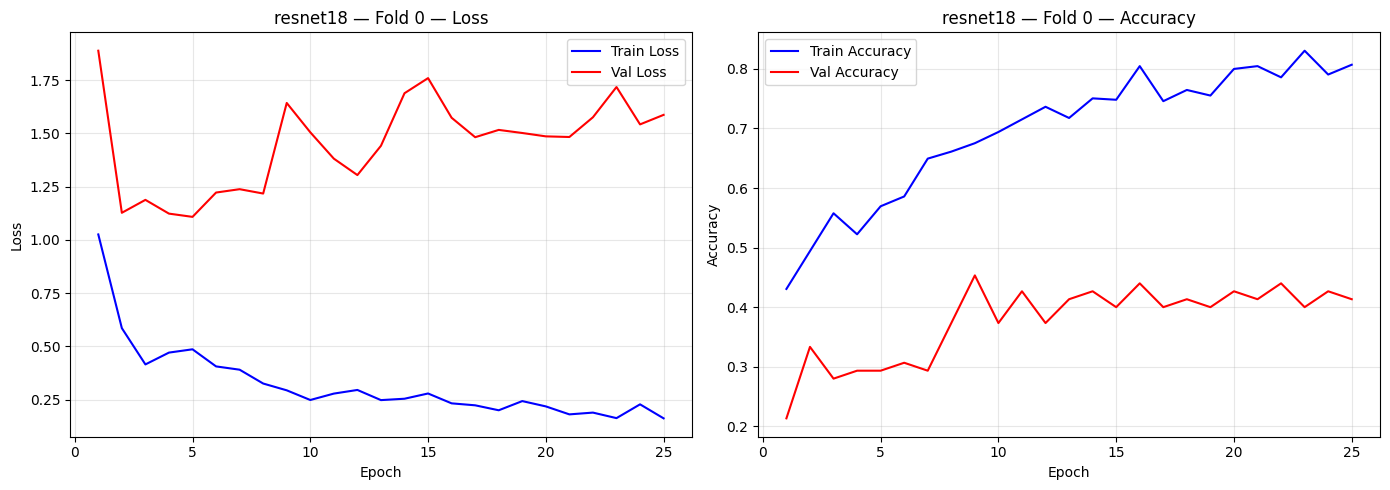


  ✓ Fold 0 — test_acc=0.4400 | test_f1=0.3639

--- Fold 1 ---
  Class weights : M0=1.968 | M1=0.577 | M2=0.636 | M3=5.312
  resnet18 — paramètres entraînables : 8,395,780 / 11,178,564 (75%)
  Epoch 01/25 | train_loss=0.8954 train_acc=0.4047 | val_loss=1.5995 val_acc=0.1733 val_f1=0.1421
  Epoch 02/25 | train_loss=0.4916 train_acc=0.5341 | val_loss=1.5415 val_acc=0.1867 val_f1=0.1589
  Epoch 03/25 | train_loss=0.5036 train_acc=0.5341 | val_loss=1.3104 val_acc=0.2533 val_f1=0.2550
  Epoch 04/25 | train_loss=0.4137 train_acc=0.5882 | val_loss=1.3388 val_acc=0.2533 val_f1=0.2428
  Epoch 05/25 | train_loss=0.4095 train_acc=0.5788 | val_loss=1.0636 val_acc=0.3467 val_f1=0.3430
  Epoch 06/25 | train_loss=0.3995 train_acc=0.5718 | val_loss=1.2226 val_acc=0.3067 val_f1=0.2361
  Epoch 07/25 | train_loss=0.4246 train_acc=0.6094 | val_loss=1.4194 val_acc=0.3067 val_f1=0.2394
  Epoch 08/25 | train_loss=0.3500 train_acc=0.6447 | val_loss=1.2506 val_acc=0.3333 val_f1=0.2640
  Epoch 09/25 | train_los

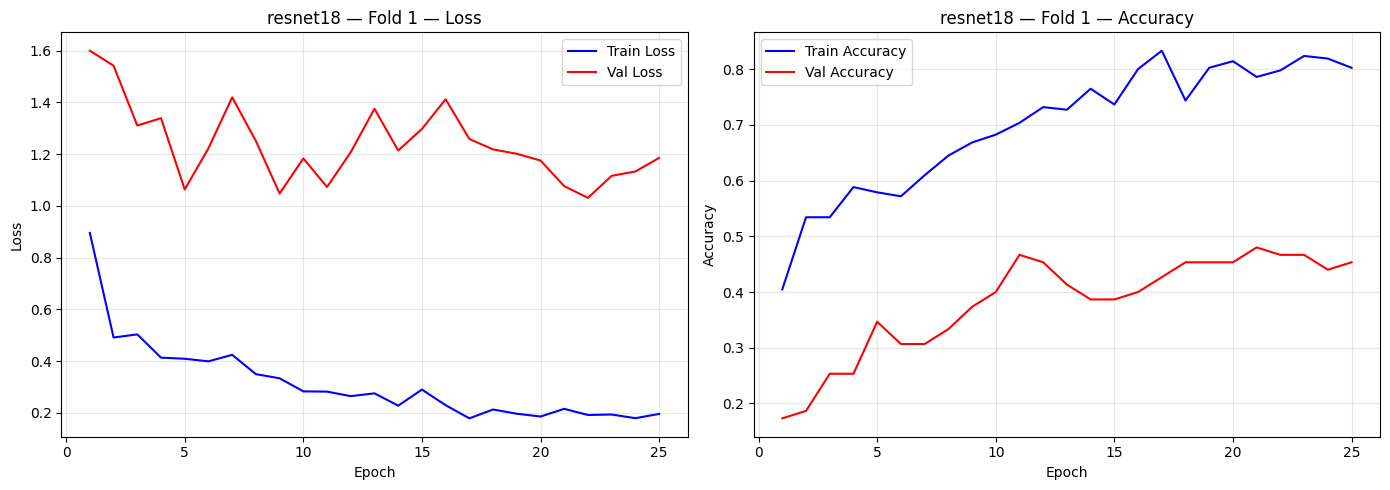


  ✓ Fold 1 — test_acc=0.4480 | test_f1=0.3744

--- Fold 2 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  resnet18 — paramètres entraînables : 8,395,780 / 11,178,564 (75%)
  Epoch 01/25 | train_loss=0.8123 train_acc=0.4094 | val_loss=1.6760 val_acc=0.1467 val_f1=0.1332
  Epoch 02/25 | train_loss=0.5538 train_acc=0.4729 | val_loss=1.4116 val_acc=0.1867 val_f1=0.1546
  Epoch 03/25 | train_loss=0.5732 train_acc=0.4776 | val_loss=1.2821 val_acc=0.2533 val_f1=0.2377
  Epoch 04/25 | train_loss=0.5387 train_acc=0.5576 | val_loss=1.3471 val_acc=0.2533 val_f1=0.2352
  Epoch 05/25 | train_loss=0.3700 train_acc=0.6165 | val_loss=1.1923 val_acc=0.2933 val_f1=0.2718
  Epoch 06/25 | train_loss=0.3453 train_acc=0.6471 | val_loss=1.2041 val_acc=0.3600 val_f1=0.3479
  Epoch 07/25 | train_loss=0.2952 train_acc=0.6847 | val_loss=1.0380 val_acc=0.3733 val_f1=0.3304
  Epoch 08/25 | train_loss=0.3966 train_acc=0.6471 | val_loss=0.9856 val_acc=0.3867 val_f1=0.3520
  Epoch 09/25 | train_los

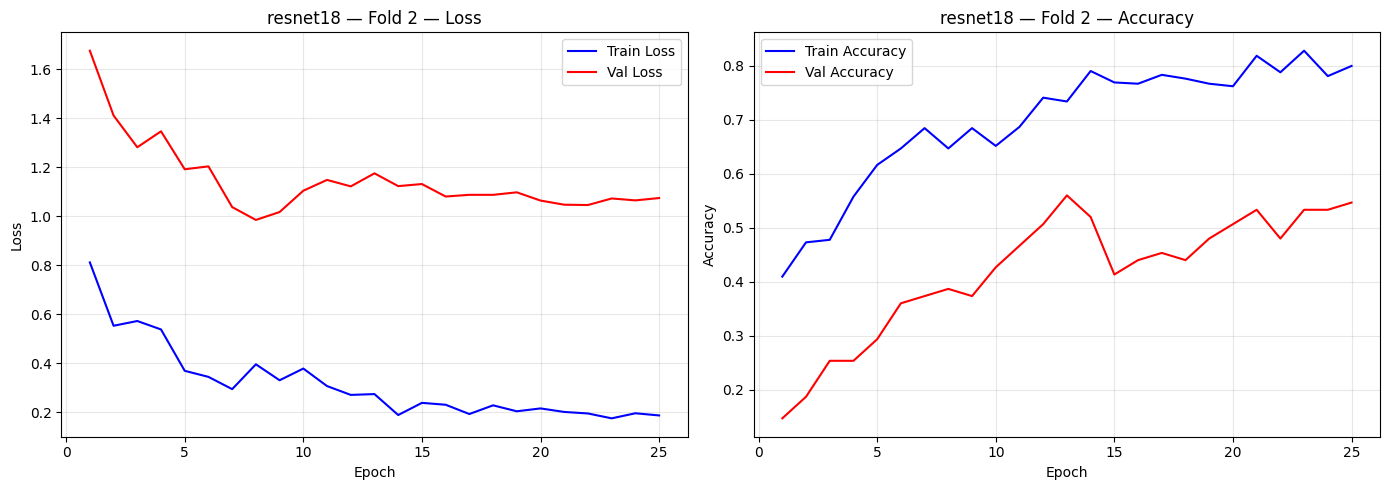


  ✓ Fold 2 — test_acc=0.4160 | test_f1=0.3193

--- Fold 3 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  resnet18 — paramètres entraînables : 8,395,780 / 11,178,564 (75%)
  Epoch 01/25 | train_loss=0.8994 train_acc=0.3812 | val_loss=1.3846 val_acc=0.1600 val_f1=0.1352
  Epoch 02/25 | train_loss=0.6026 train_acc=0.4518 | val_loss=1.2153 val_acc=0.2267 val_f1=0.2021
  Epoch 03/25 | train_loss=0.5187 train_acc=0.5059 | val_loss=1.2376 val_acc=0.2267 val_f1=0.2077
  Epoch 04/25 | train_loss=0.3754 train_acc=0.5765 | val_loss=1.0942 val_acc=0.3600 val_f1=0.3421
  Epoch 05/25 | train_loss=0.3507 train_acc=0.6282 | val_loss=1.1123 val_acc=0.4000 val_f1=0.3710
  Epoch 06/25 | train_loss=0.3463 train_acc=0.6282 | val_loss=1.0556 val_acc=0.4800 val_f1=0.4101
  Epoch 07/25 | train_loss=0.3389 train_acc=0.6659 | val_loss=1.1595 val_acc=0.4133 val_f1=0.3793
  Epoch 08/25 | train_loss=0.2934 train_acc=0.6965 | val_loss=1.1045 val_acc=0.3467 val_f1=0.3237
  Epoch 09/25 | train_los

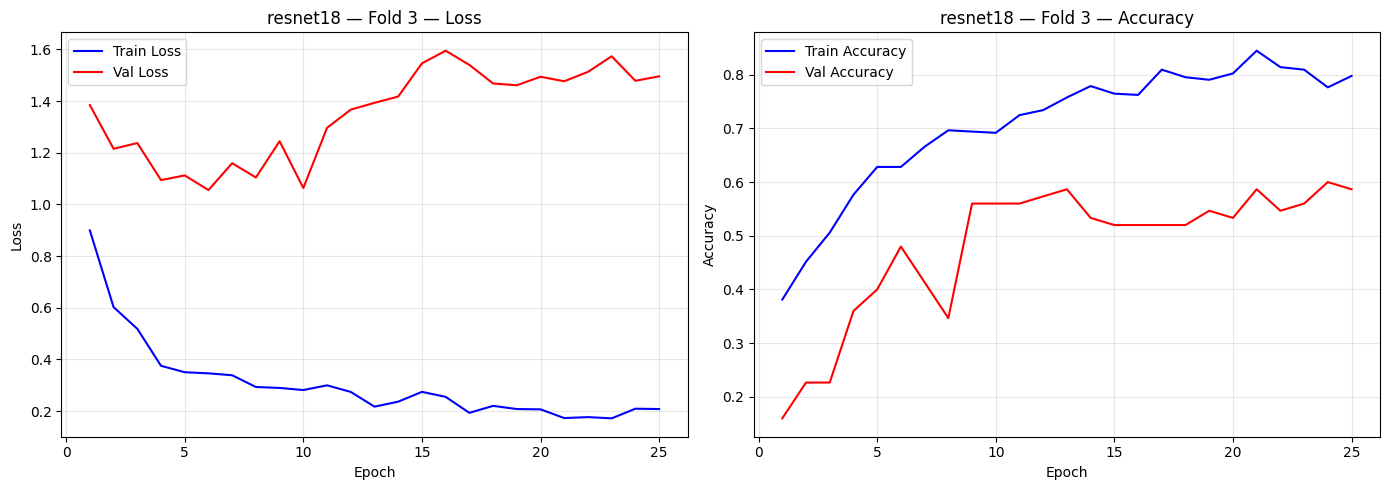


  ✓ Fold 3 — test_acc=0.4240 | test_f1=0.4216

--- Fold 4 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  resnet18 — paramètres entraînables : 8,395,780 / 11,178,564 (75%)
  Epoch 01/25 | train_loss=0.9067 train_acc=0.3694 | val_loss=1.4480 val_acc=0.1600 val_f1=0.1658
  Epoch 02/25 | train_loss=0.5286 train_acc=0.5035 | val_loss=1.8053 val_acc=0.1467 val_f1=0.1259
  Epoch 03/25 | train_loss=0.4999 train_acc=0.5012 | val_loss=1.3773 val_acc=0.2000 val_f1=0.1896
  Epoch 04/25 | train_loss=0.4753 train_acc=0.5718 | val_loss=1.5173 val_acc=0.2000 val_f1=0.2129
  Epoch 05/25 | train_loss=0.3877 train_acc=0.6329 | val_loss=1.3633 val_acc=0.2533 val_f1=0.2428
  Epoch 06/25 | train_loss=0.2637 train_acc=0.6588 | val_loss=1.4652 val_acc=0.2267 val_f1=0.2405
  Epoch 07/25 | train_loss=0.3261 train_acc=0.6541 | val_loss=1.3711 val_acc=0.3733 val_f1=0.3702
  Epoch 08/25 | train_loss=0.3421 train_acc=0.6471 | val_loss=1.5925 val_acc=0.3600 val_f1=0.3397
  Epoch 09/25 | train_los

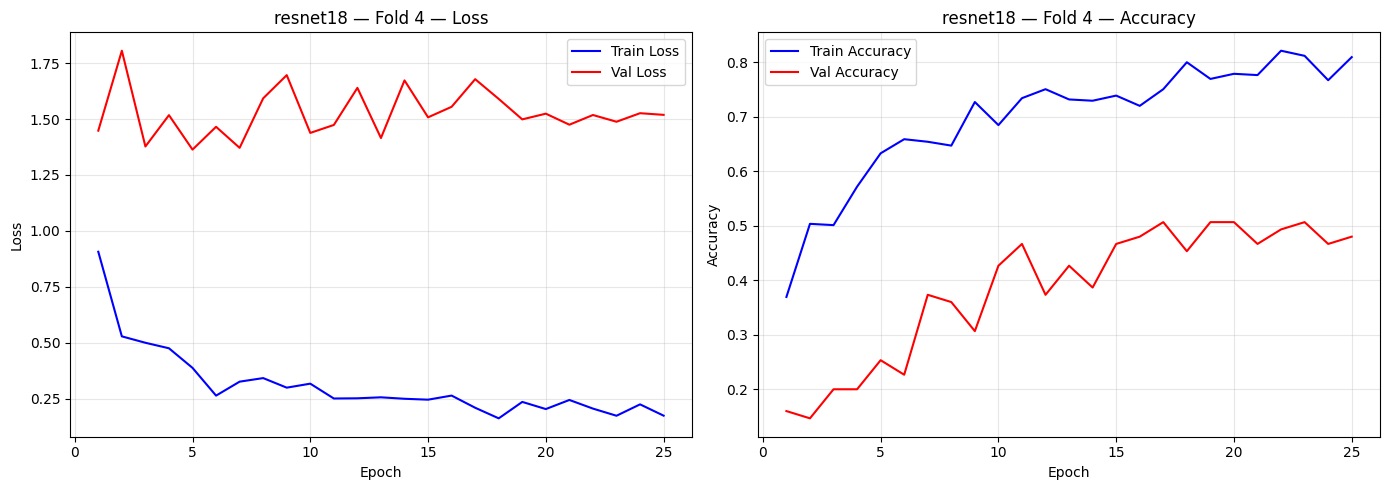


  ✓ Fold 4 — test_acc=0.4880 | test_f1=0.4321


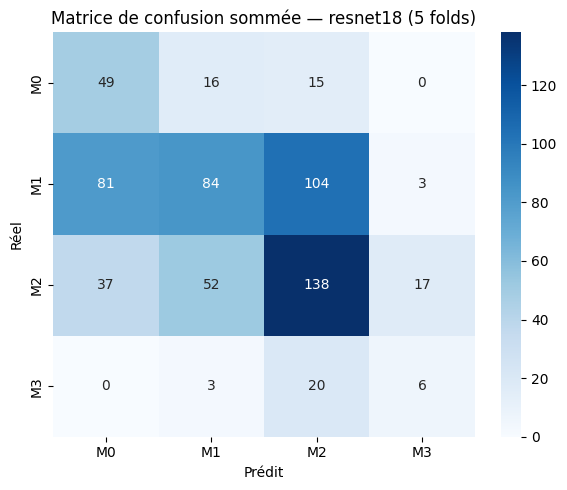


  RÉSUMÉ resnet18
  test_acc : 0.4432 ± 0.0251
  test_f1  : 0.3823 ± 0.0410
  meilleur fold : 4 (acc=0.4880)
  Résultats sauvegardés dans : /content/drive/MyDrive/bhai_classification/results/results_resnet18.json


In [11]:
results_resnet18 = train_model('resnet18')


  Modèle : resnet50 | 25 epochs | 5 folds

--- Fold 0 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 45.8MB/s]


  resnet50 — paramètres entraînables : 14,972,932 / 23,516,228 (63%)
  Epoch 01/25 | train_loss=0.7998 train_acc=0.3882 | val_loss=1.2860 val_acc=0.2400 val_f1=0.2231
  Epoch 02/25 | train_loss=0.5662 train_acc=0.4729 | val_loss=1.1447 val_acc=0.2533 val_f1=0.2444
  Epoch 03/25 | train_loss=0.3578 train_acc=0.6094 | val_loss=1.2601 val_acc=0.2267 val_f1=0.2272
  Epoch 04/25 | train_loss=0.4700 train_acc=0.5718 | val_loss=1.1244 val_acc=0.3600 val_f1=0.3257
  Epoch 05/25 | train_loss=0.4103 train_acc=0.6259 | val_loss=1.1447 val_acc=0.3200 val_f1=0.3066
  Epoch 06/25 | train_loss=0.4930 train_acc=0.5812 | val_loss=2.0047 val_acc=0.2533 val_f1=0.2349
  Epoch 07/25 | train_loss=0.3871 train_acc=0.6518 | val_loss=1.4773 val_acc=0.2533 val_f1=0.2641
  Epoch 08/25 | train_loss=0.3207 train_acc=0.6353 | val_loss=1.4609 val_acc=0.2933 val_f1=0.2884
  Epoch 09/25 | train_loss=0.3173 train_acc=0.6965 | val_loss=1.8067 val_acc=0.4133 val_f1=0.3291
  Epoch 10/25 | train_loss=0.2587 train_acc=0.710

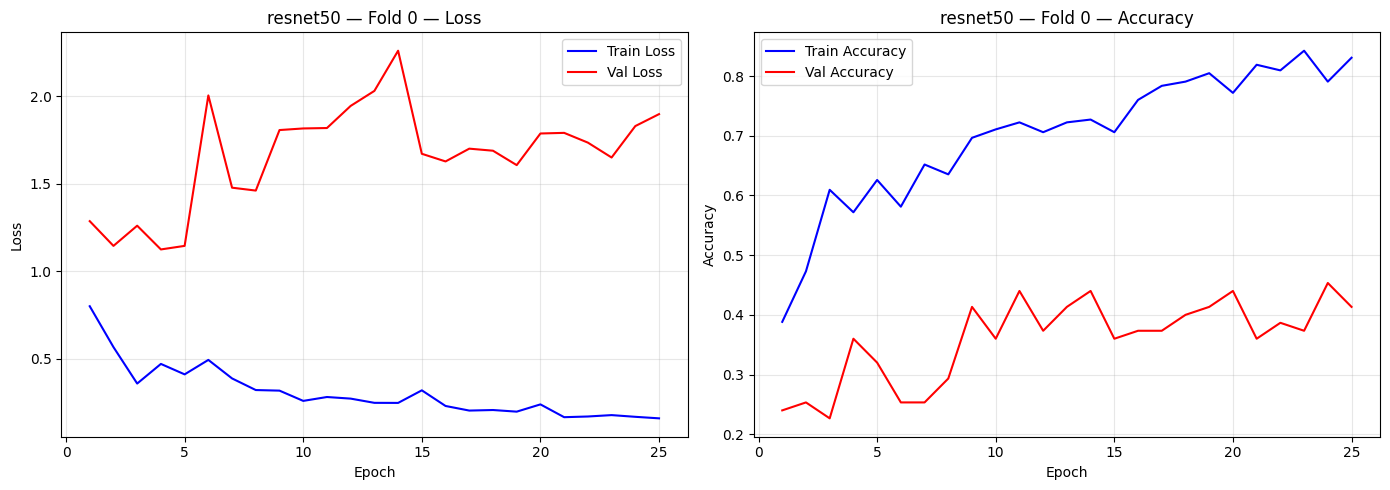


  ✓ Fold 0 — test_acc=0.4960 | test_f1=0.4275

--- Fold 1 ---
  Class weights : M0=1.968 | M1=0.577 | M2=0.636 | M3=5.312
  resnet50 — paramètres entraînables : 14,972,932 / 23,516,228 (63%)
  Epoch 01/25 | train_loss=0.7735 train_acc=0.4235 | val_loss=1.7785 val_acc=0.1600 val_f1=0.1270
  Epoch 02/25 | train_loss=0.5493 train_acc=0.4894 | val_loss=1.2468 val_acc=0.2133 val_f1=0.2012
  Epoch 03/25 | train_loss=0.4878 train_acc=0.5176 | val_loss=1.2213 val_acc=0.2667 val_f1=0.2567
  Epoch 04/25 | train_loss=0.4496 train_acc=0.5835 | val_loss=1.4000 val_acc=0.3733 val_f1=0.3452
  Epoch 05/25 | train_loss=0.3746 train_acc=0.6024 | val_loss=1.5171 val_acc=0.2933 val_f1=0.2626
  Epoch 06/25 | train_loss=0.3169 train_acc=0.6635 | val_loss=1.2766 val_acc=0.4667 val_f1=0.4592
  Epoch 07/25 | train_loss=0.3248 train_acc=0.6965 | val_loss=1.1637 val_acc=0.4533 val_f1=0.4509
  Epoch 08/25 | train_loss=0.3022 train_acc=0.6776 | val_loss=1.1724 val_acc=0.5067 val_f1=0.4735
  Epoch 09/25 | train_lo

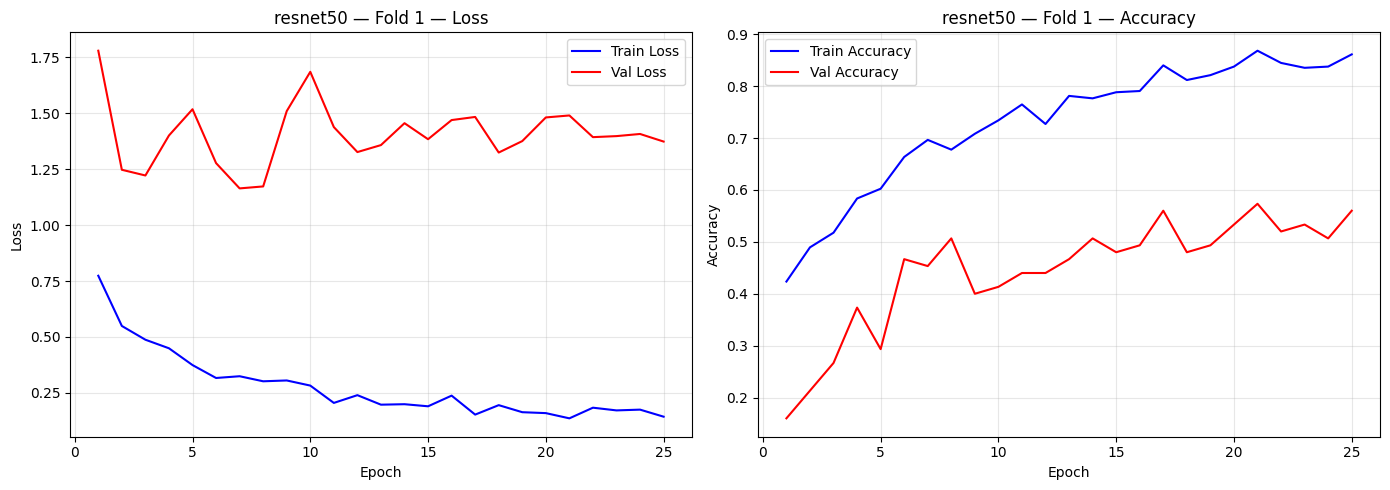


  ✓ Fold 1 — test_acc=0.4640 | test_f1=0.3143

--- Fold 2 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  resnet50 — paramètres entraînables : 14,972,932 / 23,516,228 (63%)
  Epoch 01/25 | train_loss=0.7690 train_acc=0.4400 | val_loss=1.5773 val_acc=0.1733 val_f1=0.1421
  Epoch 02/25 | train_loss=0.5340 train_acc=0.5059 | val_loss=1.5170 val_acc=0.2000 val_f1=0.2071
  Epoch 03/25 | train_loss=0.5177 train_acc=0.5482 | val_loss=1.3002 val_acc=0.2000 val_f1=0.2149
  Epoch 04/25 | train_loss=0.3724 train_acc=0.6000 | val_loss=1.1115 val_acc=0.3200 val_f1=0.3300
  Epoch 05/25 | train_loss=0.4239 train_acc=0.6071 | val_loss=1.0729 val_acc=0.4267 val_f1=0.4155
  Epoch 06/25 | train_loss=0.3683 train_acc=0.6682 | val_loss=1.2964 val_acc=0.2933 val_f1=0.2921
  Epoch 07/25 | train_loss=0.3246 train_acc=0.6847 | val_loss=1.4465 val_acc=0.3733 val_f1=0.3189
  Epoch 08/25 | train_loss=0.3249 train_acc=0.6894 | val_loss=1.2352 val_acc=0.4267 val_f1=0.3982
  Epoch 09/25 | train_lo

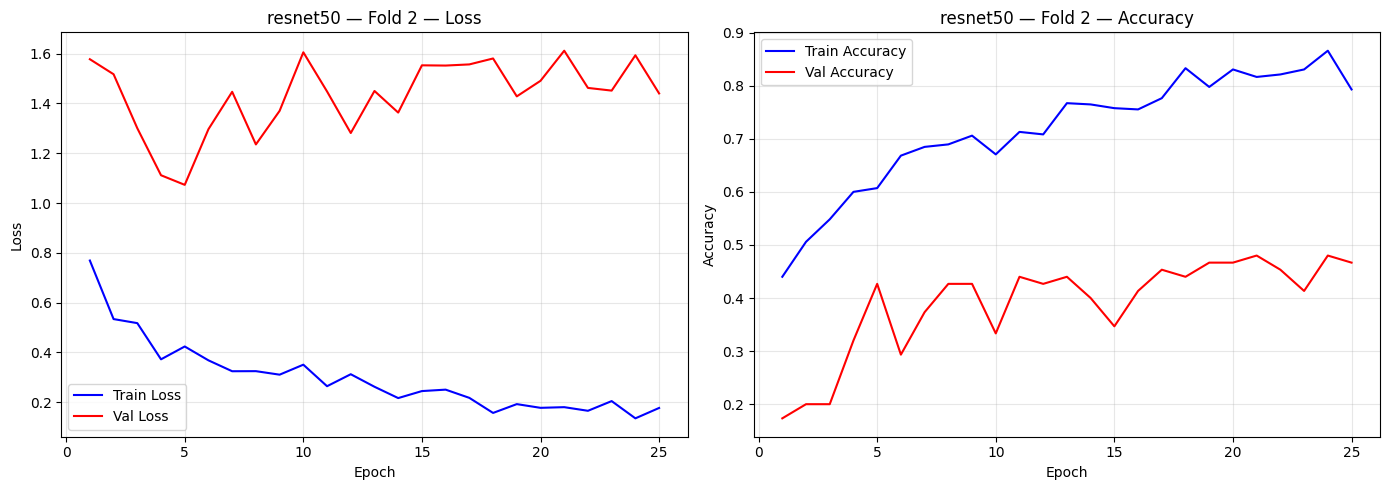


  ✓ Fold 2 — test_acc=0.4080 | test_f1=0.2930

--- Fold 3 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  resnet50 — paramètres entraînables : 14,972,932 / 23,516,228 (63%)
  Epoch 01/25 | train_loss=0.7763 train_acc=0.4165 | val_loss=1.4729 val_acc=0.1333 val_f1=0.1023
  Epoch 02/25 | train_loss=0.5016 train_acc=0.5224 | val_loss=1.3907 val_acc=0.2533 val_f1=0.2454
  Epoch 03/25 | train_loss=0.4555 train_acc=0.5529 | val_loss=1.5001 val_acc=0.2667 val_f1=0.2479
  Epoch 04/25 | train_loss=0.4012 train_acc=0.6024 | val_loss=1.1767 val_acc=0.5067 val_f1=0.4303
  Epoch 05/25 | train_loss=0.4189 train_acc=0.6118 | val_loss=1.1303 val_acc=0.4533 val_f1=0.4324
  Epoch 06/25 | train_loss=0.2656 train_acc=0.6965 | val_loss=1.1328 val_acc=0.4667 val_f1=0.4144
  Epoch 07/25 | train_loss=0.3820 train_acc=0.6518 | val_loss=1.1899 val_acc=0.4800 val_f1=0.3595
  Epoch 08/25 | train_loss=0.3076 train_acc=0.6918 | val_loss=1.2103 val_acc=0.4133 val_f1=0.3389
  Epoch 09/25 | train_lo

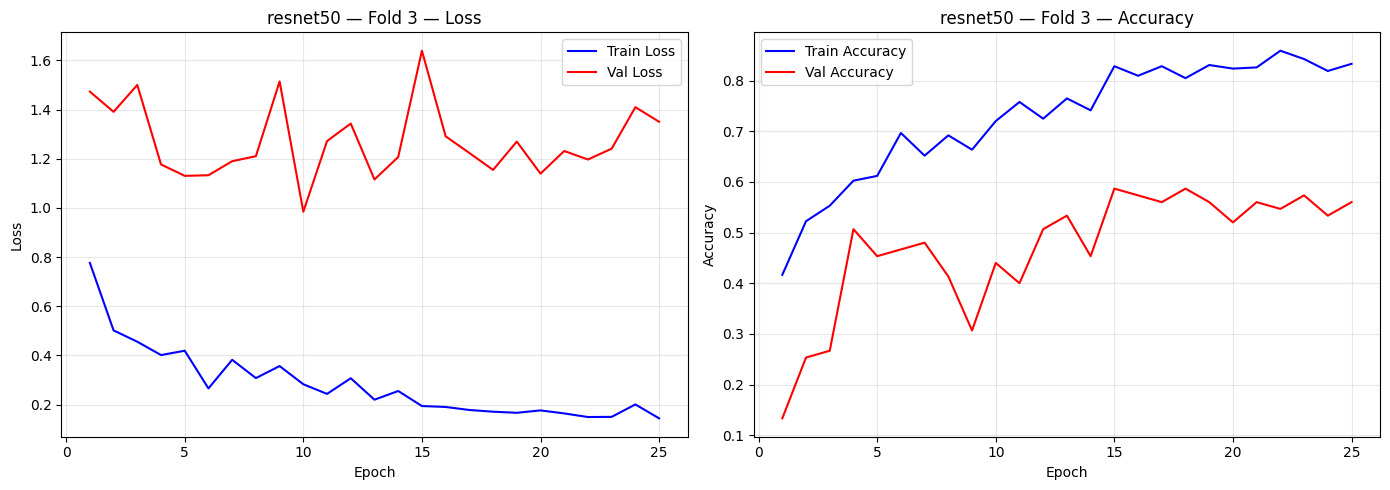


  ✓ Fold 3 — test_acc=0.4800 | test_f1=0.4122

--- Fold 4 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  resnet50 — paramètres entraînables : 14,972,932 / 23,516,228 (63%)
  Epoch 01/25 | train_loss=0.7925 train_acc=0.3835 | val_loss=1.3211 val_acc=0.1467 val_f1=0.1215
  Epoch 02/25 | train_loss=0.5405 train_acc=0.5012 | val_loss=1.1988 val_acc=0.2533 val_f1=0.3082
  Epoch 03/25 | train_loss=0.4681 train_acc=0.5859 | val_loss=1.4210 val_acc=0.2267 val_f1=0.2163
  Epoch 04/25 | train_loss=0.4029 train_acc=0.5859 | val_loss=1.1715 val_acc=0.2800 val_f1=0.2975
  Epoch 05/25 | train_loss=0.4039 train_acc=0.6259 | val_loss=1.2603 val_acc=0.4000 val_f1=0.2984
  Epoch 06/25 | train_loss=0.3610 train_acc=0.6682 | val_loss=1.2226 val_acc=0.4000 val_f1=0.4087
  Epoch 07/25 | train_loss=0.2957 train_acc=0.6588 | val_loss=1.5063 val_acc=0.4533 val_f1=0.4330
  Epoch 08/25 | train_loss=0.2852 train_acc=0.6941 | val_loss=1.4006 val_acc=0.3867 val_f1=0.3594
  Epoch 09/25 | train_lo

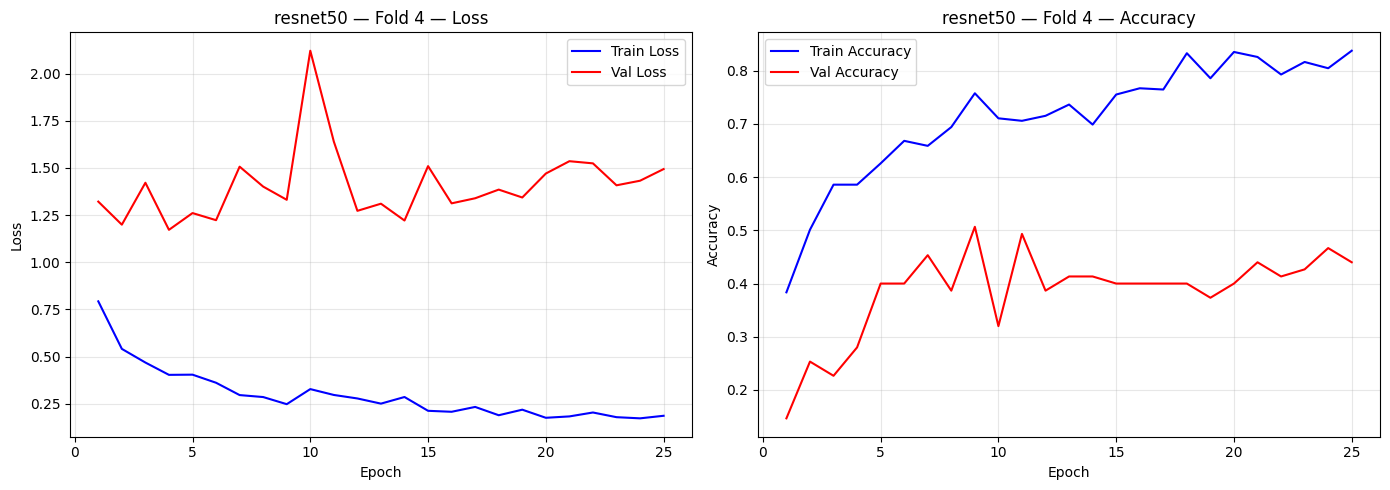


  ✓ Fold 4 — test_acc=0.4880 | test_f1=0.4311


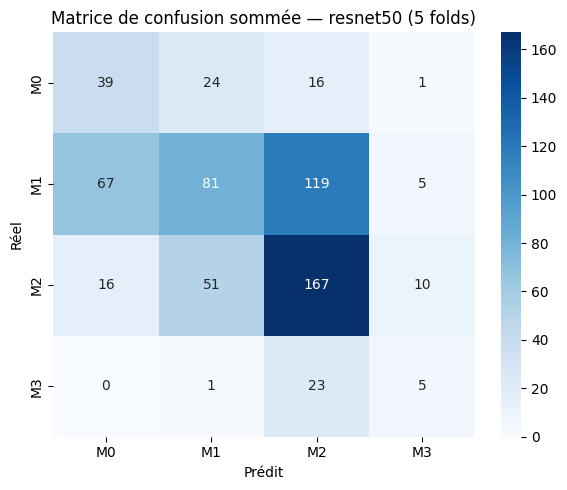


  RÉSUMÉ resnet50
  test_acc : 0.4672 ± 0.0314
  test_f1  : 0.3756 ± 0.0595
  meilleur fold : 0 (acc=0.4960)
  Résultats sauvegardés dans : /content/drive/MyDrive/bhai_classification/results/results_resnet50.json


In [12]:
results_resnet50 = train_model('resnet50')


  Modèle : efficientnet | 25 epochs | 5 folds

--- Fold 0 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 153MB/s]


  efficientnet — paramètres entraînables : 3,704,012 / 4,012,672 (92%)
  Epoch 01/25 | train_loss=1.1709 train_acc=0.3553 | val_loss=1.2548 val_acc=0.2400 val_f1=0.2202
  Epoch 02/25 | train_loss=0.7715 train_acc=0.4729 | val_loss=1.2472 val_acc=0.1867 val_f1=0.1542
  Epoch 03/25 | train_loss=0.5835 train_acc=0.4706 | val_loss=1.2253 val_acc=0.1733 val_f1=0.1450
  Epoch 04/25 | train_loss=0.5639 train_acc=0.4918 | val_loss=1.2405 val_acc=0.2133 val_f1=0.1894
  Epoch 05/25 | train_loss=0.5139 train_acc=0.4400 | val_loss=1.1897 val_acc=0.2400 val_f1=0.2211
  Epoch 06/25 | train_loss=0.4177 train_acc=0.5294 | val_loss=1.1598 val_acc=0.2267 val_f1=0.2087
  Epoch 07/25 | train_loss=0.3952 train_acc=0.5882 | val_loss=1.1711 val_acc=0.2267 val_f1=0.2129
  Epoch 08/25 | train_loss=0.3705 train_acc=0.5788 | val_loss=1.0828 val_acc=0.2667 val_f1=0.2526
  Epoch 09/25 | train_loss=0.4120 train_acc=0.5365 | val_loss=1.1157 val_acc=0.3067 val_f1=0.2936
  Epoch 10/25 | train_loss=0.3894 train_acc=0.5

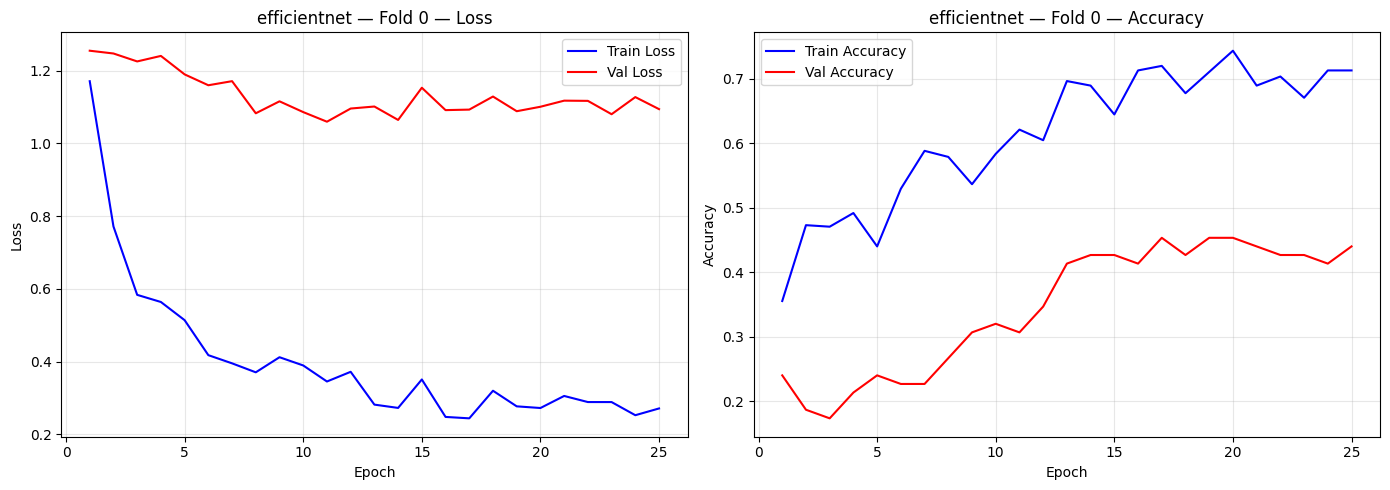


  ✓ Fold 0 — test_acc=0.4080 | test_f1=0.3604

--- Fold 1 ---
  Class weights : M0=1.968 | M1=0.577 | M2=0.636 | M3=5.312
  efficientnet — paramètres entraînables : 3,704,012 / 4,012,672 (92%)
  Epoch 01/25 | train_loss=1.2503 train_acc=0.3129 | val_loss=1.3798 val_acc=0.1733 val_f1=0.1428
  Epoch 02/25 | train_loss=0.8722 train_acc=0.4235 | val_loss=1.3408 val_acc=0.1600 val_f1=0.1275
  Epoch 03/25 | train_loss=0.6179 train_acc=0.4659 | val_loss=1.3079 val_acc=0.1733 val_f1=0.1375
  Epoch 04/25 | train_loss=0.5140 train_acc=0.4824 | val_loss=1.2538 val_acc=0.1733 val_f1=0.1369
  Epoch 05/25 | train_loss=0.5302 train_acc=0.4706 | val_loss=1.2165 val_acc=0.1733 val_f1=0.1362
  Epoch 06/25 | train_loss=0.4440 train_acc=0.5224 | val_loss=1.1652 val_acc=0.2000 val_f1=0.1715
  Epoch 07/25 | train_loss=0.4164 train_acc=0.5765 | val_loss=1.2155 val_acc=0.2000 val_f1=0.1725
  Epoch 08/25 | train_loss=0.4272 train_acc=0.5529 | val_loss=1.0574 val_acc=0.2267 val_f1=0.2074
  Epoch 09/25 | train_

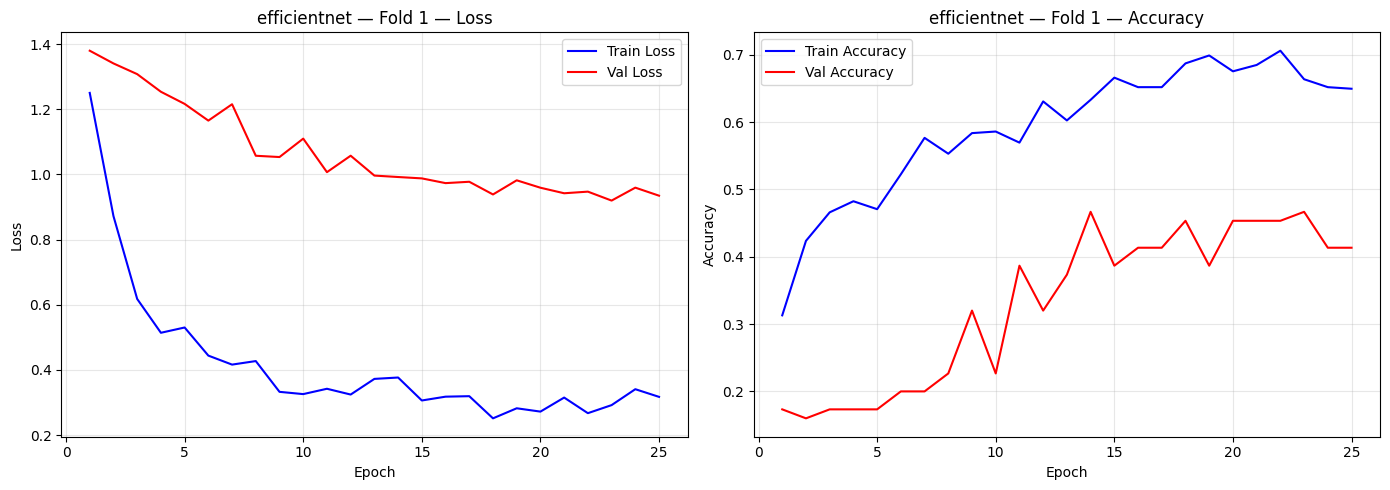


  ✓ Fold 1 — test_acc=0.3600 | test_f1=0.3508

--- Fold 2 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  efficientnet — paramètres entraînables : 3,704,012 / 4,012,672 (92%)
  Epoch 01/25 | train_loss=1.2438 train_acc=0.3694 | val_loss=1.2991 val_acc=0.2267 val_f1=0.2032
  Epoch 02/25 | train_loss=0.9151 train_acc=0.4400 | val_loss=1.2525 val_acc=0.1733 val_f1=0.1481
  Epoch 03/25 | train_loss=0.6310 train_acc=0.4706 | val_loss=1.2451 val_acc=0.1867 val_f1=0.1630
  Epoch 04/25 | train_loss=0.4988 train_acc=0.4635 | val_loss=1.2014 val_acc=0.2000 val_f1=0.1794
  Epoch 05/25 | train_loss=0.4952 train_acc=0.4941 | val_loss=1.1644 val_acc=0.2400 val_f1=0.2241
  Epoch 06/25 | train_loss=0.4803 train_acc=0.5200 | val_loss=1.1390 val_acc=0.2667 val_f1=0.2598
  Epoch 07/25 | train_loss=0.4484 train_acc=0.5318 | val_loss=1.0524 val_acc=0.3333 val_f1=0.3259
  Epoch 08/25 | train_loss=0.4337 train_acc=0.5318 | val_loss=1.0343 val_acc=0.3600 val_f1=0.3526
  Epoch 09/25 | train_

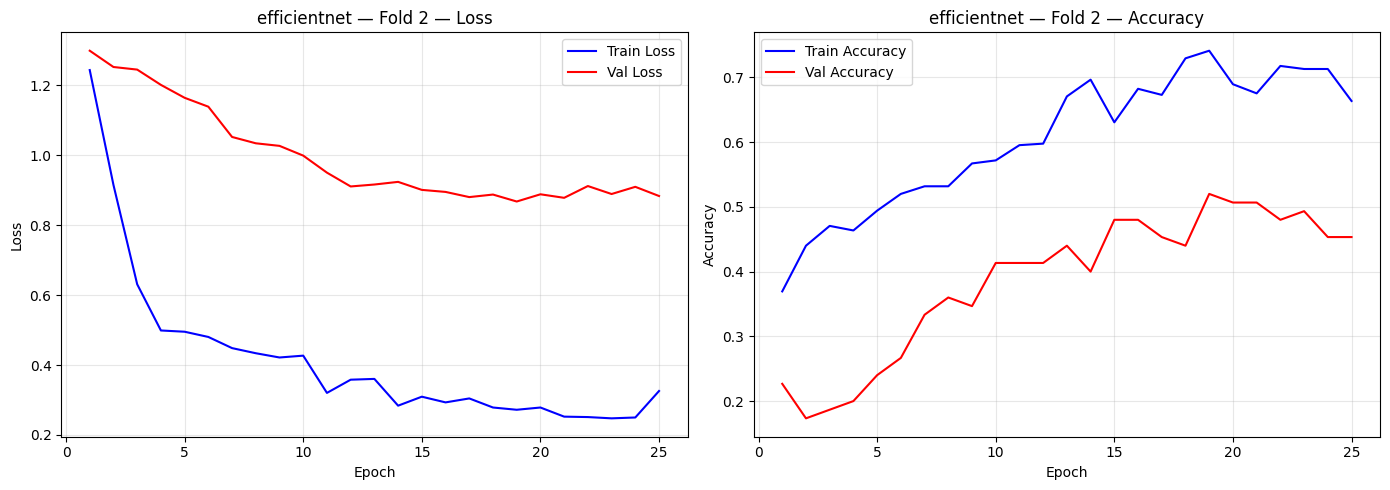


  ✓ Fold 2 — test_acc=0.4160 | test_f1=0.3288

--- Fold 3 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  efficientnet — paramètres entraînables : 3,704,012 / 4,012,672 (92%)
  Epoch 01/25 | train_loss=1.1857 train_acc=0.3435 | val_loss=1.3276 val_acc=0.1867 val_f1=0.1768
  Epoch 02/25 | train_loss=0.8513 train_acc=0.4353 | val_loss=1.4362 val_acc=0.1467 val_f1=0.1418
  Epoch 03/25 | train_loss=0.5948 train_acc=0.4729 | val_loss=1.4530 val_acc=0.1733 val_f1=0.1588
  Epoch 04/25 | train_loss=0.5418 train_acc=0.4965 | val_loss=1.4345 val_acc=0.1867 val_f1=0.1730
  Epoch 05/25 | train_loss=0.5089 train_acc=0.4753 | val_loss=1.2758 val_acc=0.2267 val_f1=0.2117
  Epoch 06/25 | train_loss=0.3812 train_acc=0.5412 | val_loss=1.2402 val_acc=0.2533 val_f1=0.2371
  Epoch 07/25 | train_loss=0.4025 train_acc=0.5153 | val_loss=1.2658 val_acc=0.2533 val_f1=0.2412
  Epoch 08/25 | train_loss=0.4108 train_acc=0.5671 | val_loss=1.1632 val_acc=0.2933 val_f1=0.2830
  Epoch 09/25 | train_

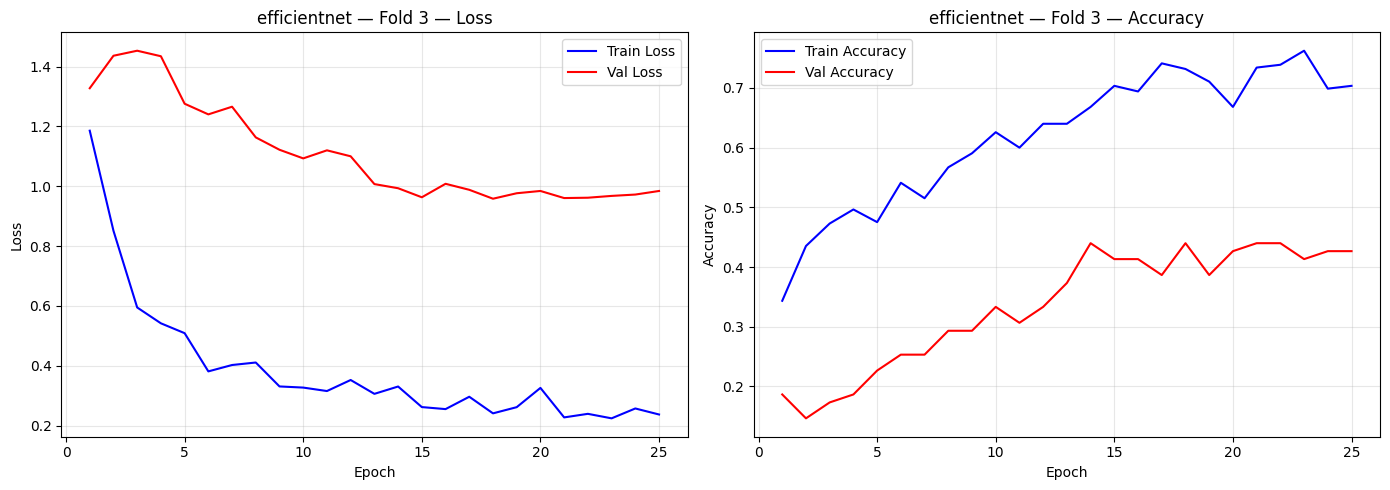


  ✓ Fold 3 — test_acc=0.4400 | test_f1=0.4041

--- Fold 4 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  efficientnet — paramètres entraînables : 3,704,012 / 4,012,672 (92%)
  Epoch 01/25 | train_loss=1.2267 train_acc=0.3576 | val_loss=1.3034 val_acc=0.1733 val_f1=0.1478
  Epoch 02/25 | train_loss=0.8013 train_acc=0.4376 | val_loss=1.2373 val_acc=0.1600 val_f1=0.1442
  Epoch 03/25 | train_loss=0.6560 train_acc=0.4471 | val_loss=1.2917 val_acc=0.1600 val_f1=0.1344
  Epoch 04/25 | train_loss=0.5320 train_acc=0.4659 | val_loss=1.2661 val_acc=0.1600 val_f1=0.1364
  Epoch 05/25 | train_loss=0.5109 train_acc=0.4894 | val_loss=1.3128 val_acc=0.1467 val_f1=0.1208
  Epoch 06/25 | train_loss=0.4433 train_acc=0.5059 | val_loss=1.2252 val_acc=0.1867 val_f1=0.1672
  Epoch 07/25 | train_loss=0.4513 train_acc=0.5082 | val_loss=1.1657 val_acc=0.2133 val_f1=0.2026
  Epoch 08/25 | train_loss=0.3859 train_acc=0.5835 | val_loss=1.1950 val_acc=0.2267 val_f1=0.2104
  Epoch 09/25 | train_

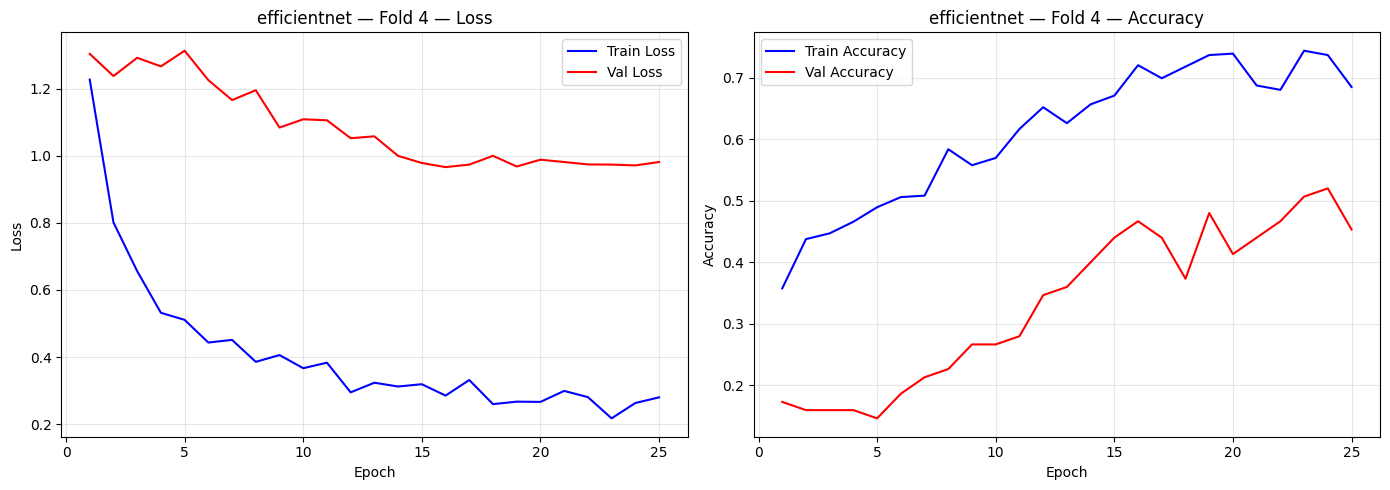


  ✓ Fold 4 — test_acc=0.5680 | test_f1=0.5213


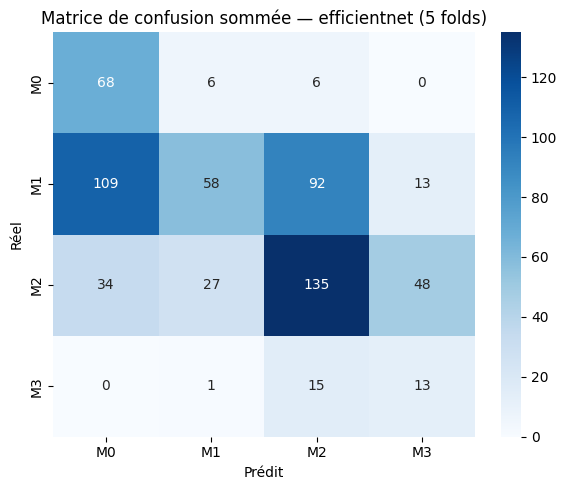


  RÉSUMÉ efficientnet
  test_acc : 0.4384 ± 0.0698
  test_f1  : 0.3931 ± 0.0686
  meilleur fold : 4 (acc=0.5680)
  Résultats sauvegardés dans : /content/drive/MyDrive/bhai_classification/results/results_efficientnet.json


In [13]:
results_efficientnet = train_model('efficientnet')


  Modèle : vit_tiny | 25 epochs | 5 folds

--- Fold 0 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

  vit_tiny — paramètres entraînables : 1,342,660 / 5,525,188 (24%)
  Epoch 01/25 | train_loss=1.0594 train_acc=0.3624 | val_loss=1.4206 val_acc=0.1600 val_f1=0.1624
  Epoch 02/25 | train_loss=0.7167 train_acc=0.4518 | val_loss=1.2288 val_acc=0.2000 val_f1=0.1788
  Epoch 03/25 | train_loss=0.6712 train_acc=0.4565 | val_loss=1.3061 val_acc=0.2000 val_f1=0.1881
  Epoch 04/25 | train_loss=0.6019 train_acc=0.5035 | val_loss=1.1325 val_acc=0.3333 val_f1=0.3286
  Epoch 05/25 | train_loss=0.6272 train_acc=0.4447 | val_loss=0.9991 val_acc=0.3333 val_f1=0.3218
  Epoch 06/25 | train_loss=0.5653 train_acc=0.4847 | val_loss=1.0788 val_acc=0.3067 val_f1=0.3189
  Epoch 07/25 | train_loss=0.5024 train_acc=0.5388 | val_loss=1.1594 val_acc=0.3733 val_f1=0.3369
  Epoch 08/25 | train_loss=0.5092 train_acc=0.5435 | val_loss=1.2142 val_acc=0.3467 val_f1=0.3494
  Epoch 09/25 | train_loss=0.5217 train_acc=0.5247 | val_loss=1.1813 val_acc=0.2533 val_f1=0.2496
  Epoch 10/25 | train_loss=0.3913 train_acc=0.5929 

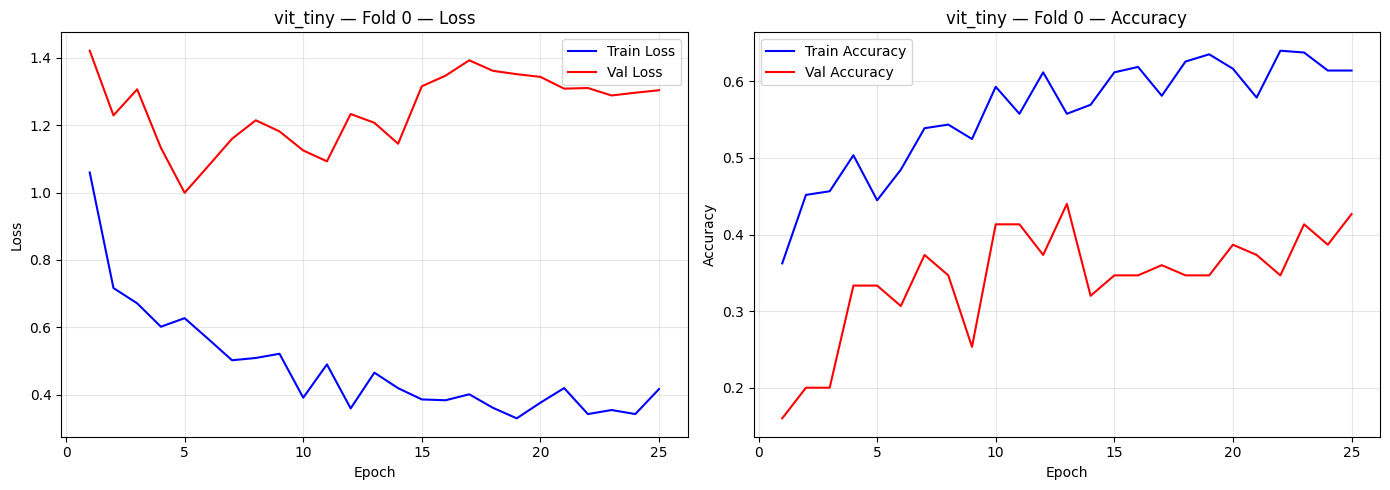


  ✓ Fold 0 — test_acc=0.4160 | test_f1=0.3303

--- Fold 1 ---
  Class weights : M0=1.968 | M1=0.577 | M2=0.636 | M3=5.312
  vit_tiny — paramètres entraînables : 1,342,660 / 5,525,188 (24%)
  Epoch 01/25 | train_loss=0.9192 train_acc=0.3906 | val_loss=1.3665 val_acc=0.1333 val_f1=0.1074
  Epoch 02/25 | train_loss=0.7940 train_acc=0.4118 | val_loss=1.4090 val_acc=0.2000 val_f1=0.1817
  Epoch 03/25 | train_loss=0.6107 train_acc=0.4871 | val_loss=1.3679 val_acc=0.1733 val_f1=0.1636
  Epoch 04/25 | train_loss=0.5800 train_acc=0.5082 | val_loss=1.2265 val_acc=0.2400 val_f1=0.2320
  Epoch 05/25 | train_loss=0.6505 train_acc=0.4682 | val_loss=1.1836 val_acc=0.2533 val_f1=0.2415
  Epoch 06/25 | train_loss=0.5595 train_acc=0.5012 | val_loss=1.4548 val_acc=0.1867 val_f1=0.1699
  Epoch 07/25 | train_loss=0.4865 train_acc=0.5506 | val_loss=1.3075 val_acc=0.2133 val_f1=0.1959
  Epoch 08/25 | train_loss=0.4997 train_acc=0.5624 | val_loss=1.3440 val_acc=0.2133 val_f1=0.2025
  Epoch 09/25 | train_loss

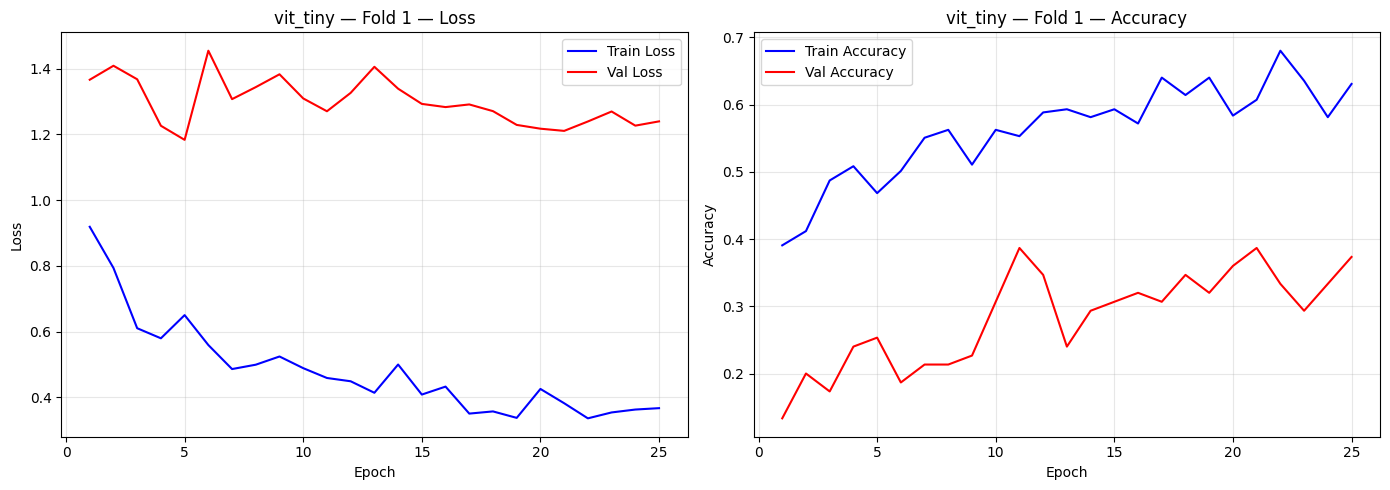


  ✓ Fold 1 — test_acc=0.4000 | test_f1=0.3924

--- Fold 2 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  vit_tiny — paramètres entraînables : 1,342,660 / 5,525,188 (24%)
  Epoch 01/25 | train_loss=0.9198 train_acc=0.3694 | val_loss=2.0050 val_acc=0.1333 val_f1=0.0649
  Epoch 02/25 | train_loss=0.6912 train_acc=0.4612 | val_loss=1.7809 val_acc=0.1600 val_f1=0.1250
  Epoch 03/25 | train_loss=0.6673 train_acc=0.5059 | val_loss=1.5540 val_acc=0.1733 val_f1=0.1370
  Epoch 04/25 | train_loss=0.4875 train_acc=0.5294 | val_loss=1.3269 val_acc=0.2400 val_f1=0.2157
  Epoch 05/25 | train_loss=0.5351 train_acc=0.4988 | val_loss=1.5184 val_acc=0.2400 val_f1=0.2379
  Epoch 06/25 | train_loss=0.6640 train_acc=0.4706 | val_loss=1.5043 val_acc=0.2800 val_f1=0.2341
  Epoch 07/25 | train_loss=0.4994 train_acc=0.5341 | val_loss=1.1541 val_acc=0.3733 val_f1=0.3289
  Epoch 08/25 | train_loss=0.4609 train_acc=0.5482 | val_loss=1.2202 val_acc=0.3600 val_f1=0.2871
  Epoch 09/25 | train_loss

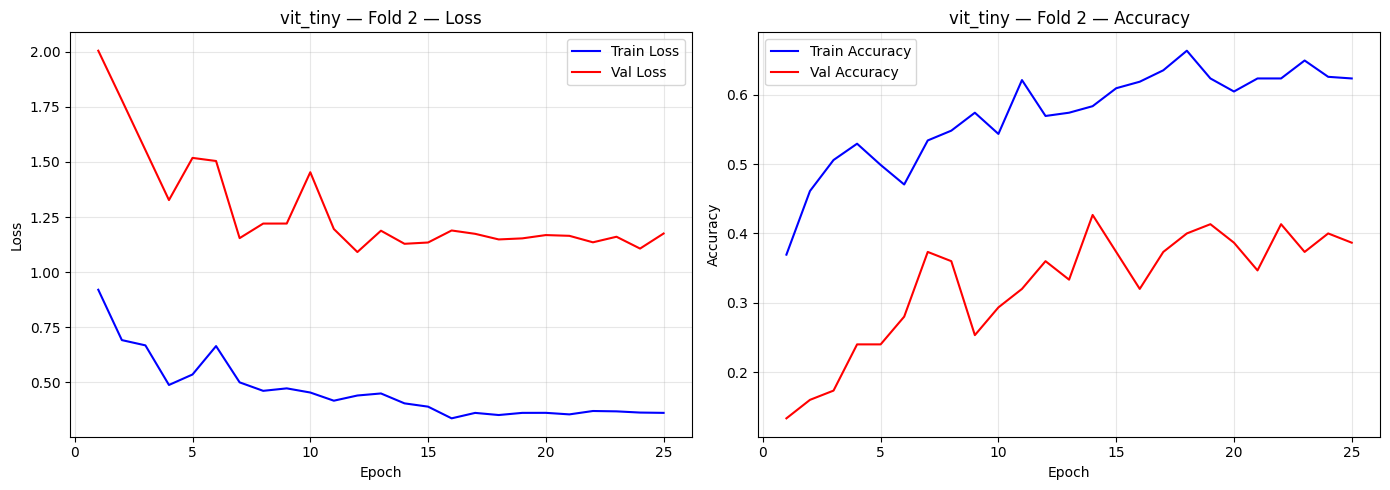


  ✓ Fold 2 — test_acc=0.4240 | test_f1=0.3603

--- Fold 3 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  vit_tiny — paramètres entraînables : 1,342,660 / 5,525,188 (24%)
  Epoch 01/25 | train_loss=1.0412 train_acc=0.3435 | val_loss=1.6217 val_acc=0.1333 val_f1=0.1070
  Epoch 02/25 | train_loss=0.8711 train_acc=0.4071 | val_loss=1.4600 val_acc=0.1733 val_f1=0.1426
  Epoch 03/25 | train_loss=0.7230 train_acc=0.4047 | val_loss=1.3686 val_acc=0.1467 val_f1=0.1134
  Epoch 04/25 | train_loss=0.6221 train_acc=0.4682 | val_loss=1.3485 val_acc=0.1867 val_f1=0.1567
  Epoch 05/25 | train_loss=0.6202 train_acc=0.4588 | val_loss=1.1408 val_acc=0.2667 val_f1=0.2379
  Epoch 06/25 | train_loss=0.5278 train_acc=0.5082 | val_loss=1.2828 val_acc=0.2533 val_f1=0.2216
  Epoch 07/25 | train_loss=0.5772 train_acc=0.5082 | val_loss=1.1611 val_acc=0.2533 val_f1=0.2359
  Epoch 08/25 | train_loss=0.4561 train_acc=0.5459 | val_loss=1.0547 val_acc=0.3200 val_f1=0.2930
  Epoch 09/25 | train_loss

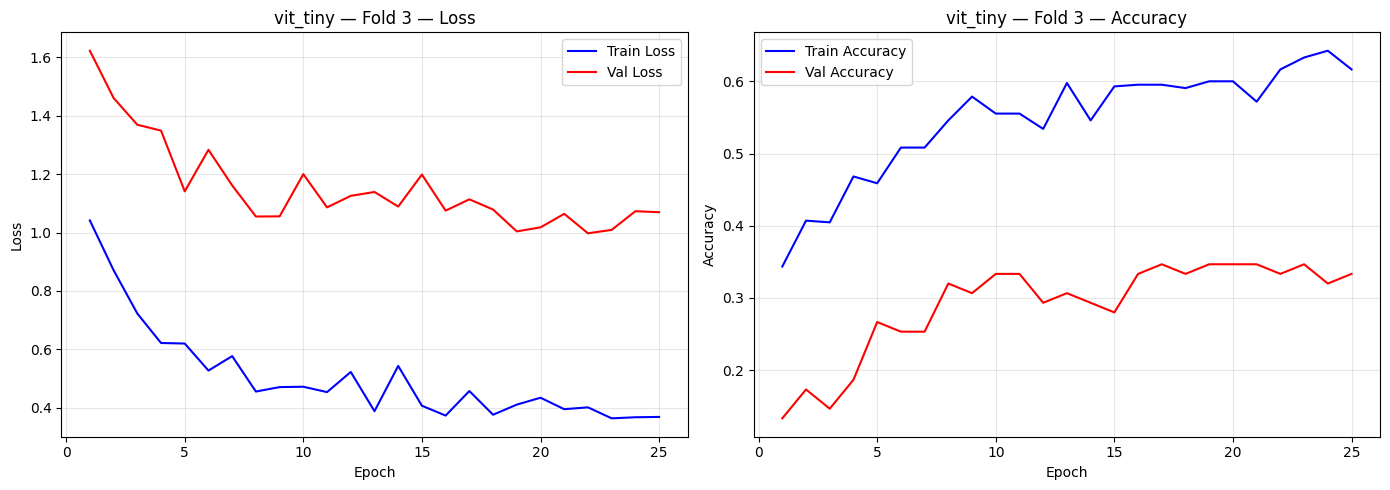


  ✓ Fold 3 — test_acc=0.3120 | test_f1=0.3065

--- Fold 4 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312
  vit_tiny — paramètres entraînables : 1,342,660 / 5,525,188 (24%)
  Epoch 01/25 | train_loss=1.0860 train_acc=0.3529 | val_loss=1.6115 val_acc=0.1067 val_f1=0.1182
  Epoch 02/25 | train_loss=0.7667 train_acc=0.4235 | val_loss=1.3357 val_acc=0.1600 val_f1=0.1487
  Epoch 03/25 | train_loss=0.6654 train_acc=0.4635 | val_loss=1.1609 val_acc=0.3467 val_f1=0.3518
  Epoch 04/25 | train_loss=0.6608 train_acc=0.4494 | val_loss=1.2646 val_acc=0.3733 val_f1=0.2525
  Epoch 05/25 | train_loss=0.5838 train_acc=0.4847 | val_loss=1.1598 val_acc=0.3600 val_f1=0.3186
  Epoch 06/25 | train_loss=0.5389 train_acc=0.5153 | val_loss=1.1526 val_acc=0.2800 val_f1=0.2704
  Epoch 07/25 | train_loss=0.5640 train_acc=0.4988 | val_loss=1.1965 val_acc=0.3067 val_f1=0.3235
  Epoch 08/25 | train_loss=0.4810 train_acc=0.5388 | val_loss=1.1659 val_acc=0.3867 val_f1=0.4121
  Epoch 09/25 | train_loss

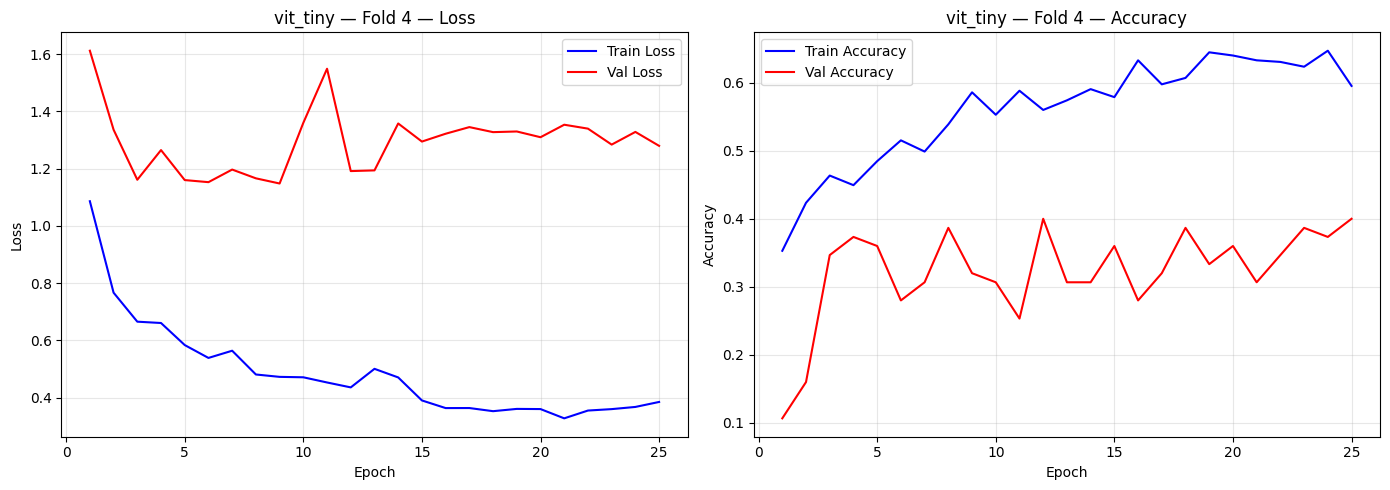


  ✓ Fold 4 — test_acc=0.2720 | test_f1=0.2656


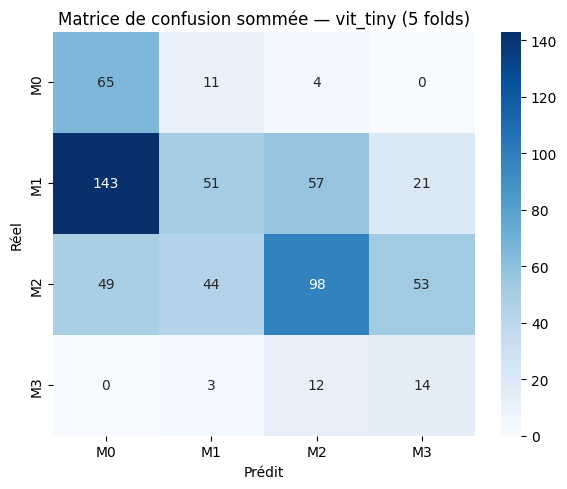


  RÉSUMÉ vit_tiny
  test_acc : 0.3648 ± 0.0613
  test_f1  : 0.3310 ± 0.0436
  meilleur fold : 2 (acc=0.4240)
  Résultats sauvegardés dans : /content/drive/MyDrive/bhai_classification/results/results_vit_tiny.json


In [14]:
!pip install timm --quiet
results_vit = train_model('vit_tiny')


  Modèle : dinov2 | 25 epochs | 5 folds

--- Fold 0 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  dinov2 — paramètres entraînables : 3,552,004 / 22,058,116 (16%)
  Epoch 01/25 | train_loss=1.5794 train_acc=0.3600 | val_loss=1.5377 val_acc=0.1600 val_f1=0.1569
  Epoch 02/25 | train_loss=0.5669 train_acc=0.5059 | val_loss=1.3041 val_acc=0.1867 val_f1=0.1514
  Epoch 03/25 | train_loss=0.4524 train_acc=0.5553 | val_loss=1.1561 val_acc=0.3067 val_f1=0.2819
  Epoch 04/25 | train_loss=0.4647 train_acc=0.5341 | val_loss=1.1203 val_acc=0.3467 val_f1=0.2856
  Epoch 05/25 | train_loss=0.4451 train_acc=0.5671 | val_loss=1.2667 val_acc=0.3867 val_f1=0.3059
  Epoch 06/25 | train_loss=0.4393 train_acc=0.5882 | val_loss=1.0761 val_acc=0.3333 val_f1=0.3055
  Epoch 07/25 | train_loss=0.3073 train_acc=0.6376 | val_loss=1.1528 val_acc=0.4400 val_f1=0.3880
  Epoch 08/25 | train_loss=0.2895 train_acc=0.6824 | val_loss=1.0933 val_acc=0.3467 val_f1=0.3330
  Epoch 09/25 | train_loss=0.2247 train_acc=0.7294 | val_loss=1.1227 val_acc=0.4133 val_f1=0.4031
  Epoch 10/25 | train_loss=0.3018 train_acc=0.7082 |

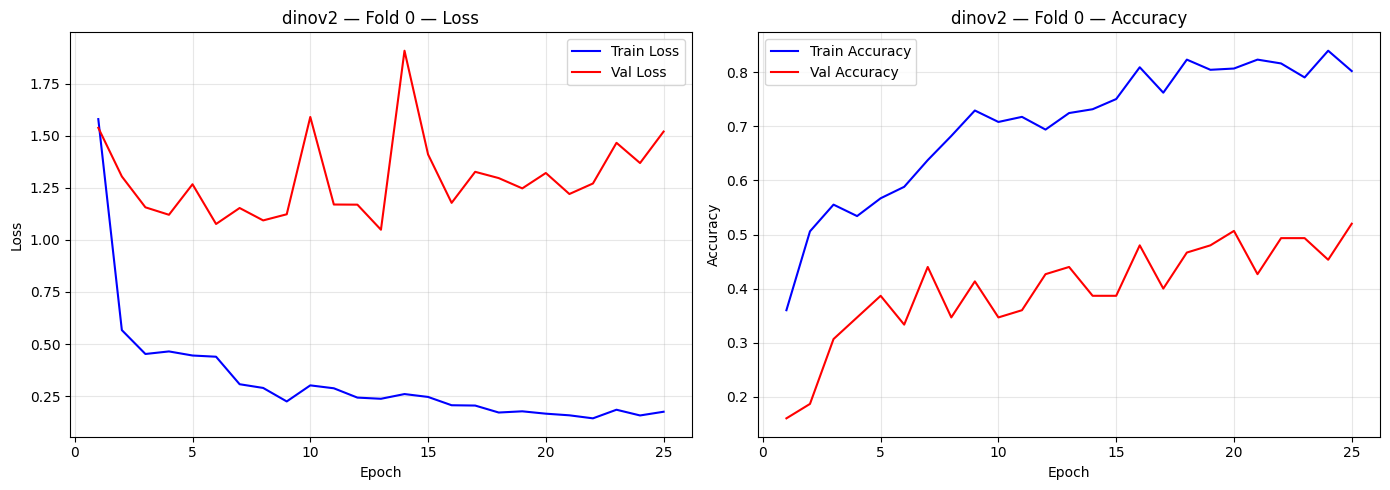


  ✓ Fold 0 — test_acc=0.5840 | test_f1=0.4793

--- Fold 1 ---
  Class weights : M0=1.968 | M1=0.577 | M2=0.636 | M3=5.312


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  dinov2 — paramètres entraînables : 3,552,004 / 22,058,116 (16%)
  Epoch 01/25 | train_loss=1.1165 train_acc=0.4518 | val_loss=1.4554 val_acc=0.2133 val_f1=0.1948
  Epoch 02/25 | train_loss=0.4630 train_acc=0.5388 | val_loss=1.4657 val_acc=0.2133 val_f1=0.1964
  Epoch 03/25 | train_loss=0.4517 train_acc=0.5694 | val_loss=1.1218 val_acc=0.2400 val_f1=0.2248
  Epoch 04/25 | train_loss=0.4269 train_acc=0.5624 | val_loss=1.1519 val_acc=0.4000 val_f1=0.3373
  Epoch 05/25 | train_loss=0.4139 train_acc=0.6212 | val_loss=1.0192 val_acc=0.4267 val_f1=0.3366
  Epoch 06/25 | train_loss=0.4179 train_acc=0.6306 | val_loss=1.8215 val_acc=0.2267 val_f1=0.2036
  Epoch 07/25 | train_loss=0.3505 train_acc=0.6306 | val_loss=1.1716 val_acc=0.2933 val_f1=0.2812
  Epoch 08/25 | train_loss=0.3056 train_acc=0.6706 | val_loss=1.1924 val_acc=0.4133 val_f1=0.3231
  Epoch 09/25 | train_loss=0.2826 train_acc=0.6682 | val_loss=1.1724 val_acc=0.3867 val_f1=0.3180
  Epoch 10/25 | train_loss=0.2378 train_acc=0.7294 |

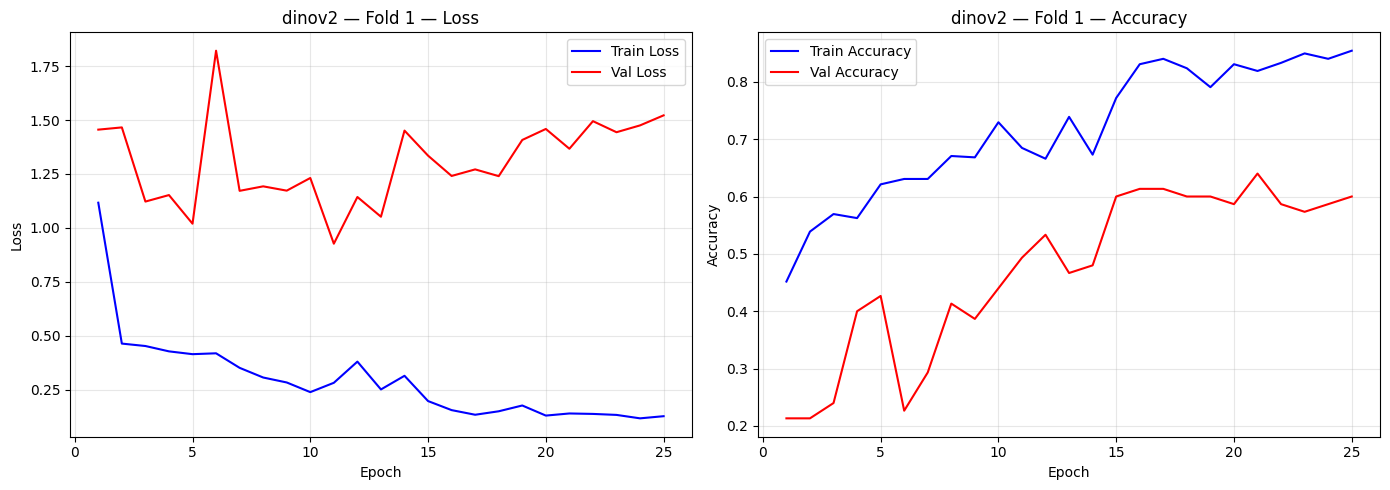


  ✓ Fold 1 — test_acc=0.6000 | test_f1=0.5003

--- Fold 2 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  dinov2 — paramètres entraînables : 3,552,004 / 22,058,116 (16%)
  Epoch 01/25 | train_loss=1.3851 train_acc=0.4188 | val_loss=1.9874 val_acc=0.1733 val_f1=0.1439
  Epoch 02/25 | train_loss=0.6239 train_acc=0.4682 | val_loss=1.1598 val_acc=0.2267 val_f1=0.2117
  Epoch 03/25 | train_loss=0.4323 train_acc=0.5718 | val_loss=1.3759 val_acc=0.2533 val_f1=0.2427
  Epoch 04/25 | train_loss=0.3852 train_acc=0.5647 | val_loss=0.9634 val_acc=0.3200 val_f1=0.3111
  Epoch 05/25 | train_loss=0.3754 train_acc=0.5953 | val_loss=1.2414 val_acc=0.2933 val_f1=0.2795
  Epoch 06/25 | train_loss=0.3169 train_acc=0.6353 | val_loss=1.2503 val_acc=0.3200 val_f1=0.3147
  Epoch 07/25 | train_loss=0.3653 train_acc=0.6471 | val_loss=0.9464 val_acc=0.3600 val_f1=0.3591
  Epoch 08/25 | train_loss=0.3296 train_acc=0.6518 | val_loss=1.1874 val_acc=0.4667 val_f1=0.4521
  Epoch 09/25 | train_loss=0.2885 train_acc=0.6894 | val_loss=2.1193 val_acc=0.2800 val_f1=0.2698
  Epoch 10/25 | train_loss=0.3934 train_acc=0.6329 |

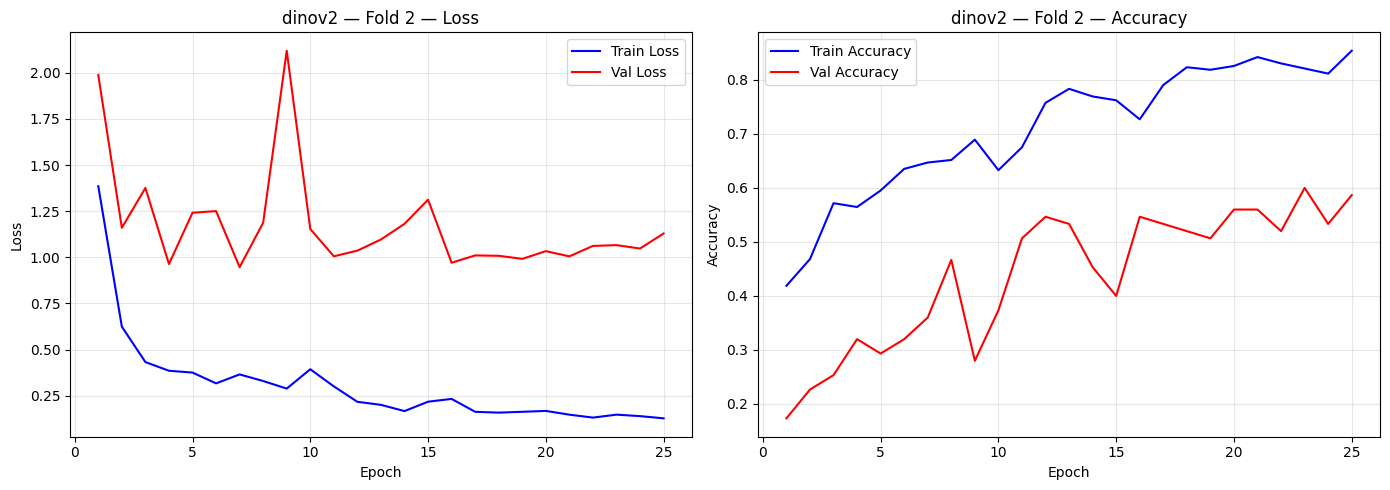


  ✓ Fold 2 — test_acc=0.5200 | test_f1=0.3998

--- Fold 3 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  dinov2 — paramètres entraînables : 3,552,004 / 22,058,116 (16%)
  Epoch 01/25 | train_loss=1.1950 train_acc=0.3882 | val_loss=1.1585 val_acc=0.2800 val_f1=0.2706
  Epoch 02/25 | train_loss=0.5113 train_acc=0.5012 | val_loss=1.5370 val_acc=0.1733 val_f1=0.1362
  Epoch 03/25 | train_loss=0.4662 train_acc=0.5200 | val_loss=1.1009 val_acc=0.4533 val_f1=0.4017
  Epoch 04/25 | train_loss=0.4391 train_acc=0.5741 | val_loss=1.3376 val_acc=0.3333 val_f1=0.3179
  Epoch 05/25 | train_loss=0.4763 train_acc=0.5600 | val_loss=1.0761 val_acc=0.2800 val_f1=0.2885
  Epoch 06/25 | train_loss=0.3541 train_acc=0.5953 | val_loss=0.9635 val_acc=0.4000 val_f1=0.3625
  Epoch 07/25 | train_loss=0.3037 train_acc=0.6471 | val_loss=1.1730 val_acc=0.3733 val_f1=0.3500
  Epoch 08/25 | train_loss=0.2309 train_acc=0.7388 | val_loss=1.3321 val_acc=0.4000 val_f1=0.3212
  Epoch 09/25 | train_loss=0.2943 train_acc=0.6847 | val_loss=1.3449 val_acc=0.5467 val_f1=0.4413
  Epoch 10/25 | train_loss=0.4220 train_acc=0.6471 |

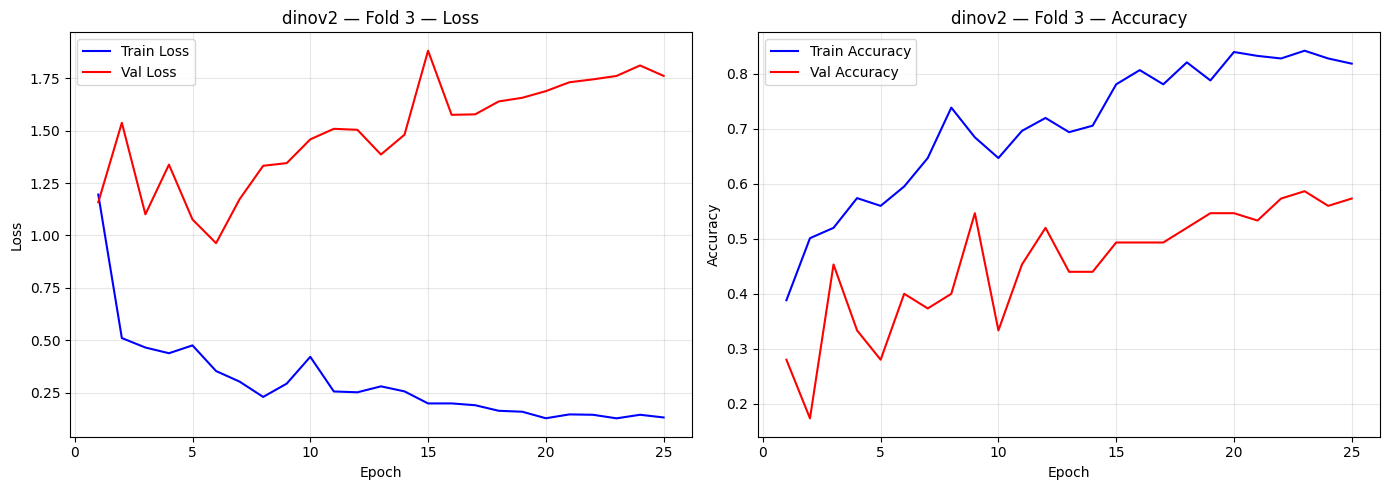


  ✓ Fold 3 — test_acc=0.5040 | test_f1=0.4659

--- Fold 4 ---
  Class weights : M0=1.968 | M1=0.574 | M2=0.640 | M3=5.312


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  dinov2 — paramètres entraînables : 3,552,004 / 22,058,116 (16%)
  Epoch 01/25 | train_loss=1.3066 train_acc=0.4776 | val_loss=2.0851 val_acc=0.1200 val_f1=0.1023
  Epoch 02/25 | train_loss=0.5513 train_acc=0.5271 | val_loss=1.2625 val_acc=0.2533 val_f1=0.2473
  Epoch 03/25 | train_loss=0.4220 train_acc=0.6000 | val_loss=1.2897 val_acc=0.2267 val_f1=0.2135
  Epoch 04/25 | train_loss=0.4123 train_acc=0.6000 | val_loss=1.2048 val_acc=0.3067 val_f1=0.2825
  Epoch 05/25 | train_loss=0.3175 train_acc=0.6165 | val_loss=1.3020 val_acc=0.2400 val_f1=0.2652
  Epoch 06/25 | train_loss=0.3184 train_acc=0.6565 | val_loss=1.0372 val_acc=0.4533 val_f1=0.4266
  Epoch 07/25 | train_loss=0.3744 train_acc=0.6306 | val_loss=1.1933 val_acc=0.3333 val_f1=0.3386
  Epoch 08/25 | train_loss=0.3530 train_acc=0.6776 | val_loss=1.3074 val_acc=0.2400 val_f1=0.2322
  Epoch 09/25 | train_loss=0.2319 train_acc=0.7412 | val_loss=1.6387 val_acc=0.5467 val_f1=0.3241
  Epoch 10/25 | train_loss=0.3218 train_acc=0.7082 |

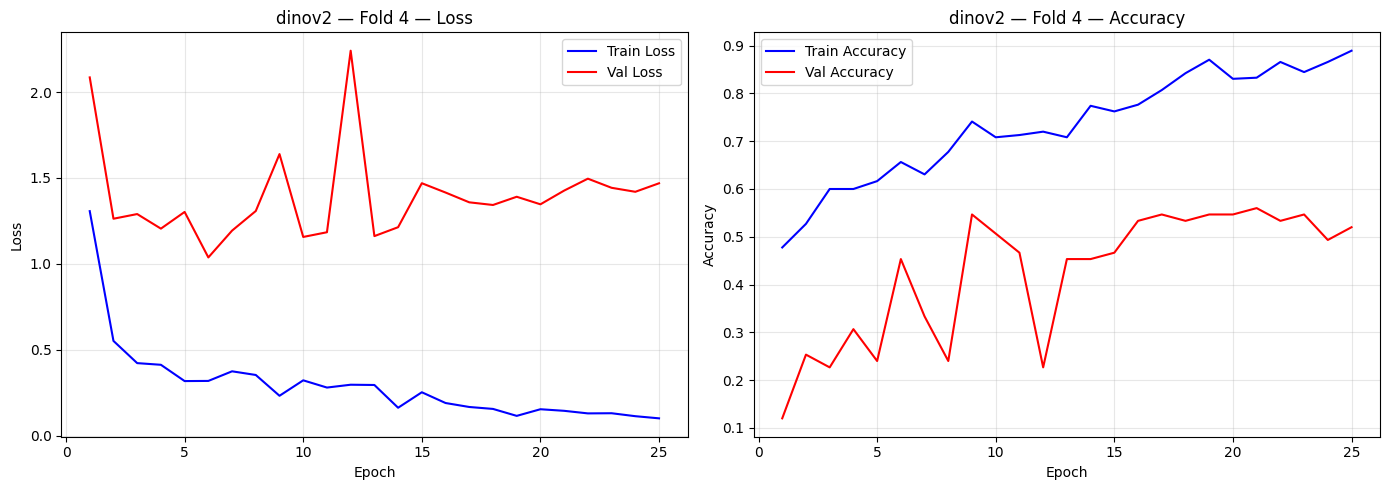


  ✓ Fold 4 — test_acc=0.5440 | test_f1=0.4175


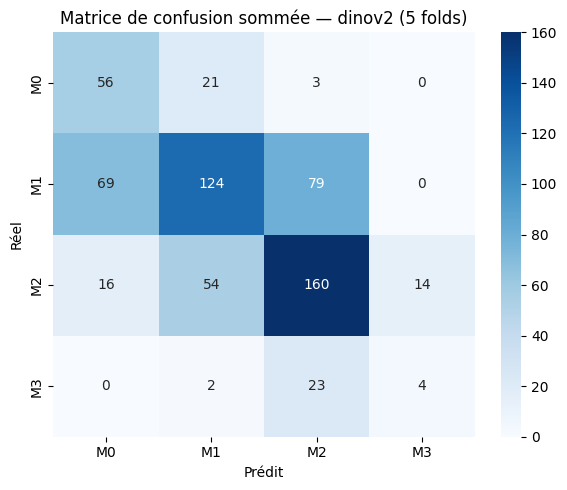


  RÉSUMÉ dinov2
  test_acc : 0.5504 ± 0.0366
  test_f1  : 0.4525 ± 0.0379
  meilleur fold : 1 (acc=0.6000)
  Résultats sauvegardés dans : /content/drive/MyDrive/bhai_classification/results/results_dinov2.json


In [15]:
!pip install transformers --quiet
results_dinov2 = train_model('dinov2')


─── Récapitulatif des résultats ─────────────────────────────
Modèle          | Acc moy    | Std      | F1 moy     | Meilleur fold
----------------------------------------------------------------------
resnet18        | 0.4432     | ±0.0251 | 0.3823     | fold 4 (acc=0.4880)
resnet50        | 0.4672     | ±0.0314 | 0.3756     | fold 0 (acc=0.4960)
efficientnet    | 0.4384     | ±0.0698 | 0.3931     | fold 4 (acc=0.5680)
vit_tiny        | 0.3648     | ±0.0613 | 0.3310     | fold 2 (acc=0.4240)


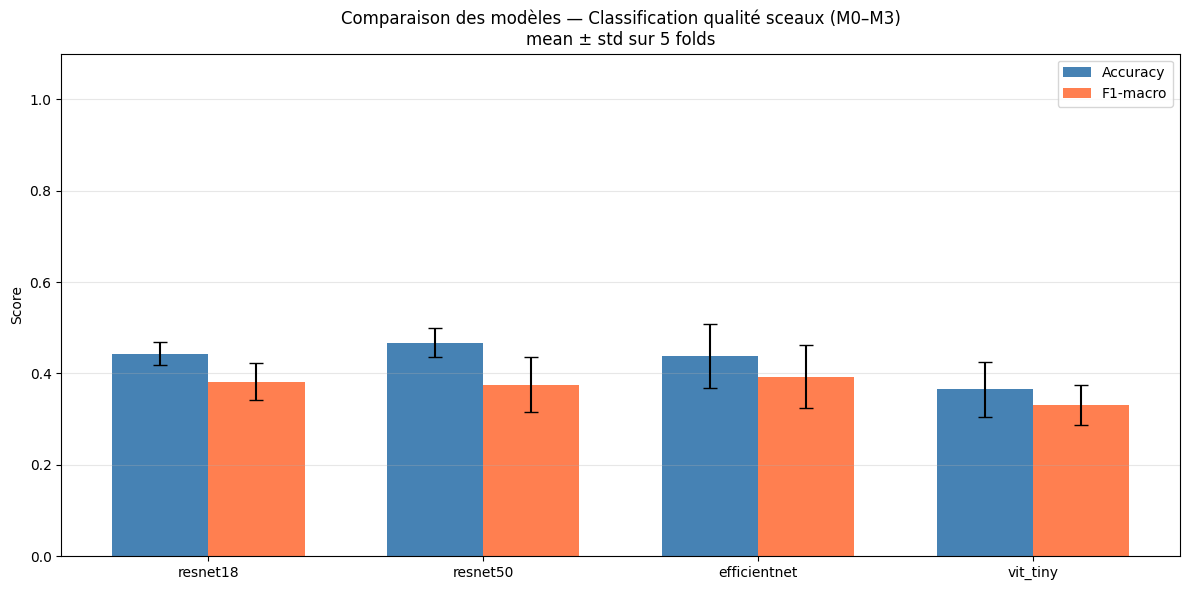

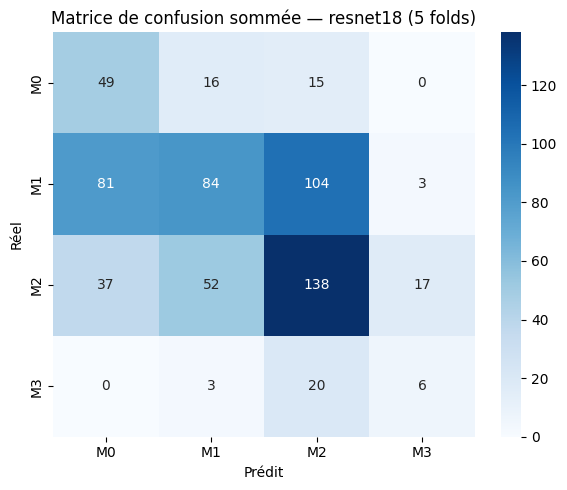

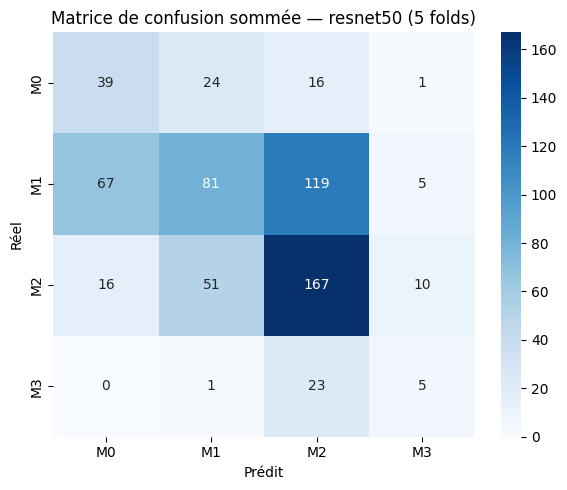

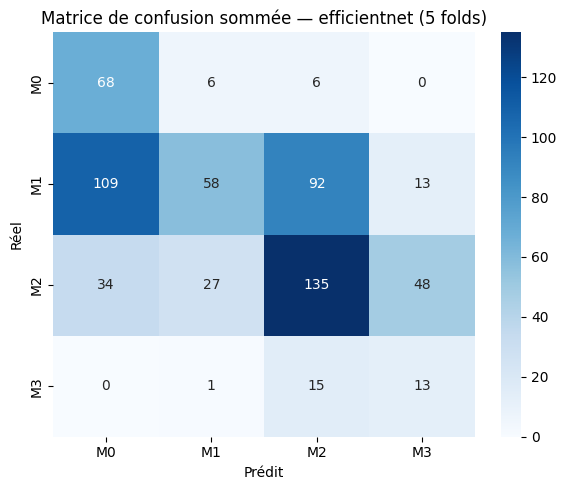

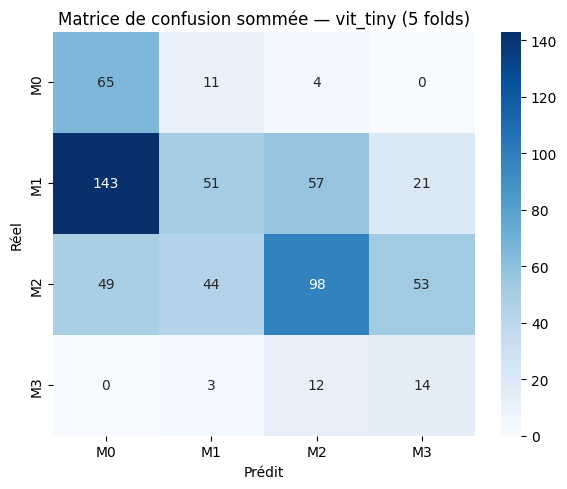


✓ all_results.json sauvegardé.


In [16]:
all_summaries = []
for model_name in ['resnet18', 'resnet50', 'efficientnet', 'vit_tiny']:
    path = os.path.join(RESULTS_DIR, f'results_{model_name}.json')
    if os.path.exists(path):
        with open(path) as f:
            all_summaries.append(json.load(f))

if not all_summaries:
    print('Aucun résultat disponible — lance d\'abord les cellules 7 à 10.')
else:
    # Tableau récapitulatif
    print('\n─── Récapitulatif des résultats ─────────────────────────────')
    print(f'{"Modèle":15s} | {"Acc moy":10s} | {"Std":8s} | {"F1 moy":10s} | Meilleur fold')
    print('-' * 70)
    for s in all_summaries:
        print(f'{s["model"]:15s} | {s["mean_test_acc"]:.4f}     | ±{s["std_test_acc"]:.4f} | {s["mean_test_f1"]:.4f}     | fold {s["best_fold"]} (acc={s["best_test_acc"]:.4f})')

    # Barplot comparatif mean ± std
    labels    = [s['model'] for s in all_summaries]
    mean_accs = [s['mean_test_acc'] for s in all_summaries]
    std_accs  = [s['std_test_acc']  for s in all_summaries]
    mean_f1s  = [s['mean_test_f1']  for s in all_summaries]
    std_f1s   = [s['std_test_f1']   for s in all_summaries]

    x, width = np.arange(len(labels)), 0.35
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x-width/2, mean_accs, width, yerr=std_accs, label='Accuracy', capsize=5, color='steelblue')
    ax.bar(x+width/2, mean_f1s,  width, yerr=std_f1s,  label='F1-macro',  capsize=5, color='coral')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel('Score')
    ax.set_title('Comparaison des modèles — Classification qualité sceaux (M0–M3)\nmean ± std sur 5 folds')
    ax.legend()
    ax.set_ylim(0, 1.1)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'comparaison_modeles.png'), dpi=150)
    plt.show()
    plt.close()

    # Matrices de confusion sommées
    for s in all_summaries:
        cm = np.array(s['summed_cm'])
        fig, ax = plt.subplots(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=ax)
        ax.set_xlabel('Prédit')
        ax.set_ylabel('Réel')
        ax.set_title(f'Matrice de confusion sommée — {s["model"]} (5 folds)')
        plt.tight_layout()
        plt.savefig(os.path.join(RESULTS_DIR, f'cm_sommee_{s["model"]}.png'), dpi=150)
        plt.show()
        plt.close()

    # Sauvegarde globale
    with open(os.path.join(RESULTS_DIR, 'all_results.json'), 'w') as f:
        json.dump(all_summaries, f, indent=2)
    print('\n✓ all_results.json sauvegardé.')

In [17]:
import os
RESULTS_DIR = '/content/drive/MyDrive/bhai_classification/results'
for f in os.listdir(RESULTS_DIR):
    if 'dino' in f.lower():
        print(f)

dinov2_fold0.pth
curves_dinov2_fold0.png
dinov2_fold1.pth
curves_dinov2_fold1.png
dinov2_fold2.pth
curves_dinov2_fold2.png
dinov2_fold3.pth
curves_dinov2_fold3.png
dinov2_fold4.pth
curves_dinov2_fold4.png
results_dinov2.json
cm_sommee_dinov2.png


In [18]:
import json
import os

RESULTS_DIR = '/content/drive/MyDrive/bhai_classification/results'

with open(os.path.join(RESULTS_DIR, 'results_dinov2.json')) as f:
    dino = json.load(f)

print(f"DINOv2 — acc={dino['mean_test_acc']:.4f} ± {dino['std_test_acc']:.4f} | f1={dino['mean_test_f1']:.4f} ± {dino['std_test_f1']:.4f}")
print(f"Meilleur fold : {dino['best_fold']} (acc={dino['best_test_acc']:.4f})")
for fd in dino['fold_details']:
    print(f"  Fold {fd['fold']} | test_acc={fd['test_acc']:.4f} | test_f1={fd['test_f1']:.4f}")

DINOv2 — acc=0.5504 ± 0.0366 | f1=0.4525 ± 0.0379
Meilleur fold : 1 (acc=0.6000)
  Fold 0 | test_acc=0.5840 | test_f1=0.4793
  Fold 1 | test_acc=0.6000 | test_f1=0.5003
  Fold 2 | test_acc=0.5200 | test_f1=0.3998
  Fold 3 | test_acc=0.5040 | test_f1=0.4659
  Fold 4 | test_acc=0.5440 | test_f1=0.4175
